In [63]:
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))


<div align="center">
  <img src="masksolutionslogo.png" alt="MASK Solutions Logo" width="350">
</div>


<div align="center">

# LE SHOPPE
## Customer Retention Intelligence
### Predictive analytics, risk prioritisation and retention decision support


---
</div>


<h1 align="center">Guide</h1>

Section | Purpose
|---|---|
| Data preparation and initial exploration | Inspect source data, missingness, distributions and candidate features |
| Customer segmentation | Explore whether behavioural clusters add useful context to churn analysis |
| Customer economics | Explore acquisition cost, lifetime value and transaction-based business measures |
| Model experimentation | Tune and compare CatBoost, Random Forest, XGBoost, LightGBM and stacking |
| Final model comparison | Compare feature sets and evaluation metrics |
| Risk labels | Convert model probabilities into operational risk tiers |
| Deployment handover | Record how the selected model is packaged and connected to the app/AWS environment |

## 1. Introduction

#### 1.1 Background

Le Shoppe currently uses two main approaches to reconnect with customers who have stopped shopping with the business or become less active. The first is an annual “welcome back” email campaign, which offers discounts to customers who have not made a purchase in 12 months. The second involves the Customer Care team contacting less active customers during quieter periods, with the option of offering discounts or free products to encourage them to return.

While these approaches can help bring customers back, they have some limitations. Both rely on staff manually generating customer lists, which takes time and requires someone with the right knowledge and access to complete the process. By the time a list reaches the Customer Care team or an offer is sent to a customer, the information may already be outdated. This means Le Shoppe may be missing opportunities to reach customers at the right time.

Another challenge is understanding why customers stop shopping with Le Shoppe. Although individual customer feedback can provide some insight, it does not necessarily show the broader patterns or behaviours that may be linked to churn.

#### 1.2 Project objectives

The aim of this project is to investigate how machine learning and predictive analytics could help Le Shoppe improve its customer retention process. 

**The project focuses on three main objectives:**

- **Identify customers at risk** of churning so that Le Shoppe can prioritise who to contact and when.

- **Identify patterns** associated with churn by exploring customer behaviour and investigating which factors may contribute to customers becoming less active.

- **Recommend ways to improve customer retention** by using the findings to suggest more targeted and effective approaches to customer outreach.

#### 1.3 Expected business value

By using customer data to identify potential churn earlier, Le Shoppe could move away from relying solely on annual campaigns and manually generated lists. Instead, the business could use predicted churn risk to help prioritise outreach, make better use of the Customer Care team's time, and provide customers with more relevant retention offers.

The project will evaluate different machine learning models to determine how effectively they identify customers at risk of churning. The results will also be used to explore potential churn drivers and develop practical recommendations for Le Shoppe's Marketing, Customer Care and Ecommerce Operations teams.

The overall goal is to develop a solution that does more than predict churn. It should help Le Shoppe understand its customers better and make more informed decisions about how to retain them.

## 2. Helper functions

Before starting the analysis, we defined a few helper functions that could be reused throughout the project. These were used to calculate ratios, evaluate model performance and group customers into different churn risk categories based on their predicted probabilities.

Having these functions available helped keep the code consistent and reduced the need to repeat the same calculations throughout the notebook.

In [5]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
import umap
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, recall_score, precision_score, f1_score, cohen_kappa_score, roc_auc_score, RocCurveDisplay
from scipy.stats import friedmanchisquare
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
from collections import Counter
import shap
import pickle

imputer = SimpleImputer(strategy='median')

In [6]:
def get_ratio(a, b):
    decimal_ratio = a / b
    
    return f"{decimal_ratio:.1f}:1"

def assign_risk_tier(prob, lowtier, medtier):
    if prob < lowtier:
        return 'Low'
    elif prob < medtier:
        return 'Med'
    else:
        return 'High'

def determine_best_risk_thresholds(y_proba, y_test, low_thresholds, med_thresholds, chosen_metric='f1_low'):
    y_test_mapped = np.where(y_test == 0, 'Low', 'High')
    results_list = []
    
    for low_t in low_thresholds:
        for med_t in med_thresholds:
            if low_t >= med_t:
                continue
                
            y_pred_risk = np.array([assign_risk_tier(p, low_t, med_t) for p in y_proba])
            
            report = classification_report(y_test_mapped,y_pred_risk,labels=['Low', 'Med', 'High'],zero_division=0,output_dict=True)
            
            results_list.append({
                'low_cutoff': low_t,
                'med_cutoff': med_t,
                'precision (low)': report['Low']['precision'],
                'recall (low)': report['Low']['recall'],
                'f1-score (low)': report['Low']['f1-score'],
                'precision (high)': report['High']['precision'],
                'recall (high)': report['High']['recall'],
                'f1-score (high)': report['High']['f1-score'],
                'accuracy': report['accuracy']
            })
            
    df_results = pd.DataFrame(results_list)
    
    if chosen_metric == 'f1_low':
        target_metric = 'f1-score (low)'
    elif chosen_metric == 'f1_high':
        target_metric = 'f1-score (high)'
    elif chosen_metric == 'precision_low':
        target_metric = 'precision (low)'
    elif chosen_metric == 'precision_high':
        target_metric = 'precision (high)'
    elif chosen_metric == 'recall_low':
        target_metric = 'recall (low)'
    elif chosen_metric == 'recall_high':
        target_metric = 'recall (high)'
    elif chosen_metric == 'accuracy':
        target_metric = 'accuracy'

    df_best = df_results.sort_values(by=target_metric, ascending=False).head(1)

    results = pd.DataFrame({"Metric": ["Precision","Recall","F1 Score"],
               "Low": [df_best['precision (low)'].iloc[0], df_best['recall (low)'].iloc[0], df_best['f1-score (low)'].iloc[0]],
               "High": [df_best['precision (high)'].iloc[0], df_best['recall (high)'].iloc[0], df_best['f1-score (high)'].iloc[0]]})

    results.set_index('Metric', inplace=True)
    results.index.rename('', inplace=True)
    print(f"""Best Results
----------------------------------------------
Low threshold: {df_best['low_cutoff'].iloc[0]}
Medium threshold: {df_best['med_cutoff'].iloc[0]}
Accuracy: {df_best['accuracy'].iloc[0]}
{results}""")

    return df_best['low_cutoff'].iloc[0], df_best['med_cutoff'].iloc[0]

def apply_risk_label(row):
    if row['churn_probability'] < 0.3:
        return 'Low'
    elif row['churn_probability'] > 0.3 and row['churn_probability'] <= 0.4:
        return 'Medium'
    else:
        return 'High'

def specificity_score(y_true, y_pred):
    return recall_score(y_true, y_pred, pos_label=0)

## 3. Data preparation and initial exploration
Before getting into the modelling, we first needed to understand the data Le Shoppe had available and whether there were any issues that could affect the results. This section explored the customer dataset, including the types of information collected, any missing values, and the behaviours that might help identify customers who were at risk of churning.
We explored the distributions of the features and how they related to each other, as well as looking at feature importance to identify which variables could be useful for predicting churn. These findings helped guide decisions around data preparation and which features to use in the models. However, feature importance showed which variables the models found useful, rather than proving that a particular behaviour caused a customer to churn.
We also documented how missing values and other data preparation steps were handled. To make sure the model evaluation was fair, preprocessing steps that learned from the data were fitted on the training set only, rather than using information from the test set.

In [7]:
churn_dataset = pd.read_csv('ecommerce_customer_churn_dataset.csv')

In [8]:
churn_dataset.dtypes

Age                              float64
Gender                            object
Country                           object
City                              object
Membership_Years                 float64
Login_Frequency                  float64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                   float64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase         float64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls           float64
Product_Reviews_Written          float64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Payment_Method_Diversity         float64
Lifetime_Value                   float64
Credit_Balance                   float64
Churned                            int64
Signup_Quarter  

In [9]:
churn_dataset.isna().sum()

Age                              2495
Gender                              0
Country                             0
City                                0
Membership_Years                    0
Login_Frequency                     0
Session_Duration_Avg             3399
Pages_Per_Session                3000
Cart_Abandonment_Rate               0
Wishlist_Items                   4000
Total_Purchases                     0
Average_Order_Value                 0
Days_Since_Last_Purchase         3000
Discount_Usage_Rate              3500
Returns_Rate                     4491
Email_Open_Rate                  2528
Customer_Service_Calls            168
Product_Reviews_Written          3500
Social_Media_Engagement_Score    6000
Mobile_App_Usage                 5000
Payment_Method_Diversity         2500
Lifetime_Value                      0
Credit_Balance                   5500
Churned                             0
Signup_Quarter                      0
dtype: int64

In [10]:
encoder = OneHotEncoder(sparse_output=False)
encoded_array = encoder.fit_transform(churn_dataset[['Gender','Country','City','Signup_Quarter']])

encoded_df = pd.DataFrame(encoded_array, columns=encoder.get_feature_names_out(['Gender','Country','City','Signup_Quarter']))
churn_dataset_encoded = churn_dataset.drop(['Gender','Country','City','Signup_Quarter'], axis=1)
churn_dataset_encoded = pd.concat([churn_dataset_encoded, encoded_df], axis=1)

In [11]:
y = churn_dataset_encoded['Churned']
X = churn_dataset_encoded.drop('Churned', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [12]:
rf_helper = RandomForestClassifier(n_estimators=100, random_state=42)
rf_helper.fit(X_train, y_train)

importances = rf_helper.feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)

In [13]:
top20feature_importance_df = feature_importance_df.head(20)
top20feature_importance_df

,Feature,Importance
13,Customer_Service_Calls,0.113862
18,Lifetime_Value,0.108101
5,Cart_Abandonment_Rate,0.082969
0,Age,0.061734
10,Discount_Usage_Rate,0.056280
9,Days_Since_Last_Purchase,0.052057
12,Email_Open_Rate,0.045517
8,Average_Order_Value,0.043546
7,Total_Purchases,0.042794
3,Session_Duration_Avg,0.042641


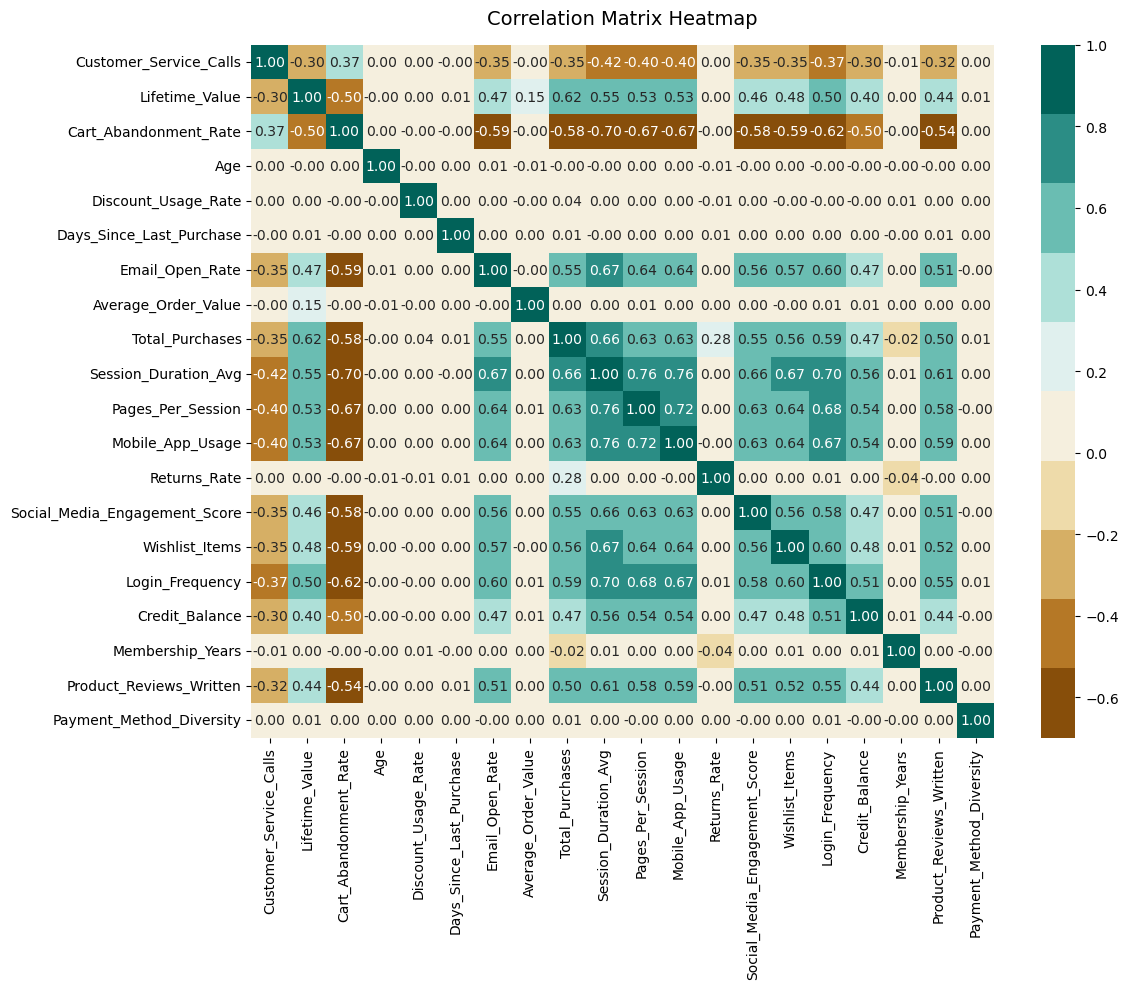

In [14]:
feature_names_top20 = top20feature_importance_df['Feature'].tolist()

corr_matrix = churn_dataset_encoded[feature_names_top20].corr()

plt.figure(figsize=(12, 10))
colormap = sns.color_palette("BrBG",10)

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap=colormap)

plt.title("Correlation Matrix Heatmap", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### Initial feature selection findings

The initial feature importance results and correlation heatmap helped identify which variables might be useful for predicting customer churn. Lifetime value stood out as the strongest feature, while several customer engagement and purchasing behaviours also appeared worth investigating.

Based on these initial findings, the features were grouped according to their potential usefulness:

**Strongest feature**
- `Lifetime_Value`

**Supporting features (higher correlation)**
- `Total_Purchases`
- `Session_Duration_Average`
- `Pages_Per_Session`
- `Mobile_App_Usage`
- `Login_Frequency`
- `Cart_Abandonment_Rate`

**Potentially helpful features (moderate correlation)**
- `Social_Media_Engagement_Score`
- `Wishlist_Items`
- `Credit_Balance`
- `Product_Reviews_Written`
- `Email_Open_Rate`

**Features with weaker correlations**
- `Average_Order_Value`
- `Returns_Rate`
- `Customer_Service_Calls`

**Features with little to no correlation**
- `Age`
- `Discount_Usage_Rate`
- `Days_Since_Last_Purchase`
- `Membership_Years`
- `Payment_Method_Diversity`

These groupings provided an initial guide for feature selection rather than a final decision about which variables to use. The features were also assessed during model experimentation to see how different combinations affected predictive performance. A low correlation on its own did not necessarily mean a feature would be unhelpful to a model.

In [15]:
columns_to_initially_keep = ['Gender','Country','City'] + feature_names_top20 + ['Churned']
churn_df = churn_dataset[columns_to_initially_keep]
columns_to_drop = ['Age','Discount_Usage_Rate','Days_Since_Last_Purchase','Membership_Years','Payment_Method_Diversity','Customer_Service_Calls']
churn_df = churn_df.drop(columns=columns_to_drop)
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Gender                         50000 non-null  object 
 1   Country                        50000 non-null  object 
 2   City                           50000 non-null  object 
 3   Lifetime_Value                 50000 non-null  float64
 4   Cart_Abandonment_Rate          50000 non-null  float64
 5   Email_Open_Rate                47472 non-null  float64
 6   Average_Order_Value            50000 non-null  float64
 7   Total_Purchases                50000 non-null  float64
 8   Session_Duration_Avg           46601 non-null  float64
 9   Pages_Per_Session              47000 non-null  float64
 10  Mobile_App_Usage               45000 non-null  float64
 11  Returns_Rate                   45509 non-null  float64
 12  Social_Media_Engagement_Score  44000 non-null 

## 4. Customer segmentation

Understanding which customers may leave is important, but it can also be useful to understand how customer behaviours differ across the dataset. For example, some customers may shop frequently and spend more, while others may interact less with the website or abandon their carts more often.

To explore these patterns, we used K-means clustering to group customers with similar behavioural characteristics. Unlike the churn prediction models, which estimate the likelihood of a customer churning, clustering looks for similarities between customers without directly predicting an outcome.

The aim was to explore whether these groups could provide additional context for Le Shoppe's retention strategy, such as helping the business understand different customer behaviours and consider whether different groups may benefit from different engagement approaches.

### 4.1 Preparing customer data for segmentation

Before identifying groups of similar customers, we prepared the dataset by selecting the features to include in the analysis and removing variables that were not intended to contribute to the clustering. Rows with missing values were also removed, and the remaining features were standardised so that variables with larger numerical scales would not automatically have more influence on the results.

This prepared dataset was then used to explore whether customers could be grouped according to similarities in their behaviour.

In [16]:
kmeans_df = churn_dataset.drop(columns=['Age','Gender','Country','City','Signup_Quarter','Returns_Rate','Discount_Usage_Rate','Days_Since_Last_Purchase','Membership_Years','Payment_Method_Diversity','Customer_Service_Calls']).copy()
kmeans_df.dropna(inplace=True)
y_kmeans = kmeans_df['Churned']
X_kmeans = kmeans_df.drop('Churned', axis=1)

scaler = StandardScaler()
X_kmeans_scaled = scaler.fit_transform(X_kmeans)

### 4.2 Choosing the number of customer groups

We tested between two and six customer groups to find an option that best represented the patterns in the data. Since the appropriate number of groups was not known in advance, we compared the results using three measures of clustering quality.

The silhouette score measures how well customers fit within their assigned group, where higher scores are generally better. The Davies–Bouldin index measures how similar groups are to one another, where lower scores are generally better. The Calinski–Harabasz index compares how separated the groups are, where higher scores are generally better.

Looking at all three measures helped us compare the options rather than choosing a number of groups arbitrarily.

In [17]:
k_range = range(2, 7)
silhouette_scores = []
davies_bouldin_scores = []
calinski_harabasz_scores = []

for k in k_range:
    km_model = KMeans(n_clusters=k, init='k-means++', random_state=42)
    km_model.fit(X_kmeans_scaled)
    results = km_model.predict(X_kmeans_scaled)

    silhouette_scores.append(metrics.silhouette_score(X_kmeans_scaled, results))
    davies_bouldin_scores.append(metrics.davies_bouldin_score(X_kmeans_scaled, results))
    calinski_harabasz_scores.append(metrics.calinski_harabasz_score(X_kmeans_scaled, results))

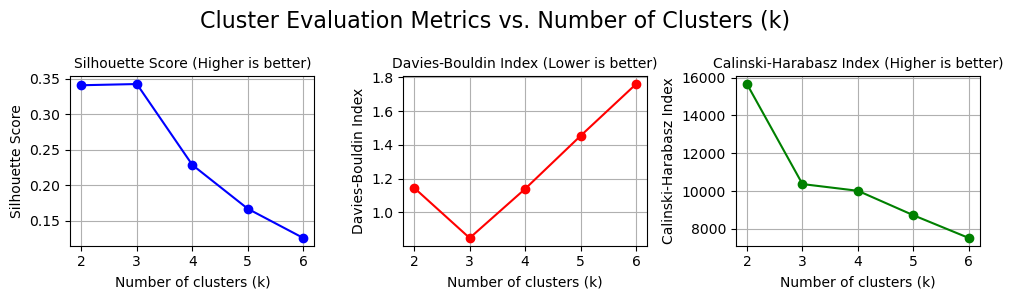

In [18]:
fig = plt.figure(figsize=(10, 3))
gs = gridspec.GridSpec(1, 3, figure=fig, height_ratios=[1])
fig.suptitle('Cluster Evaluation Metrics vs. Number of Clusters (k)', fontsize=16)

ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(k_range, silhouette_scores, 'bo-')
ax1.set_xlabel('Number of clusters (k)', fontsize=10)
ax1.set_ylabel('Silhouette Score', fontsize=10)
ax1.set_title('Silhouette Score (Higher is better)', fontsize=10)
ax1.grid(True)

ax2 = fig.add_subplot(gs[0, 1])
ax2.plot(k_range, davies_bouldin_scores, 'ro-')
ax2.set_xlabel('Number of clusters (k)', fontsize=10)
ax2.set_ylabel('Davies-Bouldin Index', fontsize=10)
ax2.set_title('Davies-Bouldin Index (Lower is better)', fontsize=10)
ax2.grid(True)

ax3 = fig.add_subplot(gs[0, 2])
ax3.plot(k_range, calinski_harabasz_scores, 'go-')
ax3.set_xlabel('Number of clusters (k)', fontsize=10)
ax3.set_ylabel('Calinski-Harabasz Index', fontsize=10)
ax3.set_title('Calinski-Harabasz Index (Higher is better)', fontsize=10)
ax3.grid(True)

plt.tight_layout(); plt.show()

### 4.3 Creating and visualising customer segments

After selecting three clusters as the preferred option from the earlier evaluation, we used K-means to group customers based on similarities in their selected behavioural features.

We then used UMAP to create a two-dimensional visualisation of these groups. This makes it easier to see how the clusters are positioned relative to one another and whether customer behaviours appear distinct or overlap. The visualisation provides an overview of the groups, while further analysis is needed to understand the specific characteristics of each one.

In [19]:
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)

cluster_labels = kmeans.fit_predict(X_kmeans_scaled)

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1)
X_umap = reducer.fit_transform(X_kmeans_scaled)

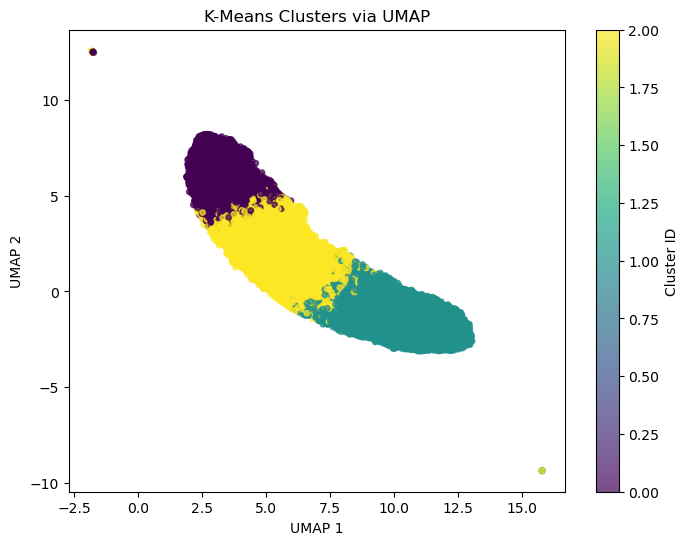

In [20]:
plt.figure(figsize=(8, 6)); scatter = plt.scatter(X_umap[:, 0],X_umap[:, 1],c=cluster_labels,cmap="viridis",s=15,alpha=0.7)
plt.colorbar(scatter, label="Cluster ID"); plt.xlabel("UMAP 1"); plt.ylabel("UMAP 2"); plt.title("K-Means Clusters via UMAP"); plt.show()

**Interpreting the cluster evaluation results**

The evaluation measures produced mixed results when comparing the number of customer groups. Two clusters performed best on the silhouette and Calinski–Harabasz measures, while three clusters had the lowest Davies–Bouldin score. This meant there was no single option that performed best across all three measures.

Three clusters were selected for the next stage of the analysis to explore whether this grouping provided useful differences in customer behaviour. The resulting groups were then visualised and examined further to understand whether they offered meaningful insights for Le Shoppe.

In [21]:
kmean_groups = X_kmeans.copy(); kmean_groups['Cluster'] = cluster_labels
kmean_groups['Churned'] = y_kmeans

cluster_summary = kmean_groups.groupby('Cluster').mean(); 
cluster_table = cluster_summary.sort_values(by='Churned', ascending=True)

In [22]:
summary_values = {"Feature": ['Login_Frequency','Session_Duration_Avg', 'Pages_Per_Session', 'Wishlist_Items', 
                          'Total_Purchases','Average_Order_Value','Email_Open_Rate','Product_Reviews_Written',
                          'Social_Media_Engagement_Score','Mobile_App_Usage','Lifetime_Value','Credit_Balance','Churned'],
    "Min": [kmeans_df.Login_Frequency.min(), kmeans_df.Session_Duration_Avg.min(), kmeans_df.Pages_Per_Session.min(), kmeans_df.Wishlist_Items.min(), kmeans_df.Total_Purchases.min(), kmeans_df.Average_Order_Value.min(), kmeans_df.Email_Open_Rate.min(), kmeans_df.Product_Reviews_Written.min(), kmeans_df.Social_Media_Engagement_Score.min(), kmeans_df.Mobile_App_Usage.min(), kmeans_df.Lifetime_Value.min(), kmeans_df.Credit_Balance.min(), kmeans_df.Churned.min()],
    "Q1": [kmeans_df.Login_Frequency.quantile(0.25), kmeans_df.Session_Duration_Avg.quantile(0.25), kmeans_df.Pages_Per_Session.quantile(0.25), kmeans_df.Wishlist_Items.quantile(0.25), kmeans_df.Total_Purchases.quantile(0.25), kmeans_df.Average_Order_Value.quantile(0.25), kmeans_df.Email_Open_Rate.quantile(0.25), kmeans_df.Product_Reviews_Written.quantile(0.25), kmeans_df.Social_Media_Engagement_Score.quantile(0.25), kmeans_df.Mobile_App_Usage.quantile(0.25), kmeans_df.Lifetime_Value.quantile(0.25), kmeans_df.Credit_Balance.quantile(0.25), kmeans_df.Churned.quantile(0.25)],
    "Median": [kmeans_df.Login_Frequency.median(), kmeans_df.Session_Duration_Avg.median(), kmeans_df.Pages_Per_Session.median(), kmeans_df.Wishlist_Items.median(), kmeans_df.Total_Purchases.median(), kmeans_df.Average_Order_Value.median(), kmeans_df.Email_Open_Rate.median(), kmeans_df.Product_Reviews_Written.median(), kmeans_df.Social_Media_Engagement_Score.median(), kmeans_df.Mobile_App_Usage.median(), kmeans_df.Lifetime_Value.median(), kmeans_df.Credit_Balance.median(), kmeans_df.Churned.median()],    
    "Q3": [kmeans_df.Login_Frequency.quantile(0.75), kmeans_df.Session_Duration_Avg.quantile(0.75), kmeans_df.Pages_Per_Session.quantile(0.75), kmeans_df.Wishlist_Items.quantile(0.75), kmeans_df.Total_Purchases.quantile(0.75), kmeans_df.Average_Order_Value.quantile(0.75), kmeans_df.Email_Open_Rate.quantile(0.75), kmeans_df.Product_Reviews_Written.quantile(0.75), kmeans_df.Social_Media_Engagement_Score.quantile(0.75), kmeans_df.Mobile_App_Usage.quantile(0.75), kmeans_df.Lifetime_Value.quantile(0.75), kmeans_df.Credit_Balance.quantile(0.75), kmeans_df.Churned.quantile(0.75)],
    "Max": [kmeans_df.Login_Frequency.max(), kmeans_df.Session_Duration_Avg.max(), kmeans_df.Pages_Per_Session.max(), kmeans_df.Wishlist_Items.max(), kmeans_df.Total_Purchases.max(), kmeans_df.Average_Order_Value.max(), kmeans_df.Email_Open_Rate.max(), kmeans_df.Product_Reviews_Written.max(), kmeans_df.Social_Media_Engagement_Score.max(), kmeans_df.Mobile_App_Usage.max(), kmeans_df.Lifetime_Value.max(), kmeans_df.Credit_Balance.max(), kmeans_df.Churned.max()]}

summary_stats = pd.DataFrame(summary_values)

In [23]:
summary_stats.sort_values('Max', ascending=False).style.set_caption('Summary Statistics for Churn Data').format(precision=2)

,Feature,Min,Q1,Median,Q3,Max
5,Average_Order_Value,26.87,87.04,112.21,143.75,9487.43
10,Lifetime_Value,0.00,833.23,1299.56,1933.79,8987.24
11,Credit_Balance,0.00,1122.00,1987.00,2872.50,7160.00
4,Total_Purchases,-13.00,9.00,13.00,17.00,127.40
8,Social_Media_Engagement_Score,0.00,14.50,29.20,44.90,100.00
6,Email_Open_Rate,0.00,10.60,20.60,31.20,91.70
1,Session_Duration_Avg,1.00,20.10,27.30,35.20,72.10
9,Mobile_App_Usage,0.00,13.20,19.60,26.40,61.90
0,Login_Frequency,0.00,6.00,12.00,18.00,46.00
2,Pages_Per_Session,1.00,6.30,8.80,11.60,23.20


In [24]:
cluster_table.style.set_caption('Cluster Summary').format(precision=2)

,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Email_Open_Rate,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Lifetime_Value,Credit_Balance,Churned
Cluster,,,,,,,,,,,,,,
0,21.81,42.50,13.87,36.39,8.30,21.74,124.44,38.36,5.56,54.89,32.33,2418.30,3291.82,0.20
2,13.42,29.80,9.64,52.97,4.91,14.51,123.83,23.24,3.26,33.21,21.50,1580.46,2167.09,0.20
1,6.21,18.76,5.90,68.15,2.12,8.31,119.78,10.99,1.40,15.59,12.29,907.72,1249.04,0.38


In [25]:
risk_map = {0: "low", 1: "high", 2: "medium"}
kmean_groups['Churn_Risk'] = kmean_groups['Cluster'].map(risk_map)
kmean_groups.head(5)

,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Email_Open_Rate,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Lifetime_Value,Credit_Balance,Cluster,Churned,Churn_Risk
0,14.0,27.4,6.0,50.6,3.0,9.0,94.72,17.9,4.0,16.3,20.8,953.33,2278.0,2,0,medium
3,10.0,38.4,14.8,41.7,9.0,15.0,147.33,41.4,5.0,85.9,31.0,2340.92,2674.0,0,0,low
5,6.0,21.9,6.9,74.4,0.0,12.0,190.97,16.0,2.0,14.3,11.2,1995.43,2418.0,1,1,high
6,24.0,46.4,13.9,36.2,5.0,20.0,169.58,35.5,6.0,68.8,42.9,3003.57,2657.0,0,0,low
9,13.0,31.3,5.4,62.6,3.0,9.0,90.95,11.7,1.0,13.5,21.5,807.84,977.0,1,0,high


### 4.4 Interpreting the Customer Segments

The cluster summary helps us get a better understanding of how customers differ in their shopping behaviour and engagement with Le Shoppe. Looking at the average values for each group gives us an idea of which customers are more active, which spend more, and which groups may need more attention when it comes to retention.

**Cluster 0 — Higher engagement and customer value**

Customers in Cluster 0 are the most active group overall. They have the highest average login frequency (21.81), session duration (42.50) and pages per session (13.87). They also make the most purchases on average (21.74) and have the highest lifetime value (2,418.30). The average churn rate for this group is 20%. This suggests that these customers are generally more engaged with the business and contribute more value. Le Shoppe could focus on keeping these customers satisfied and encouraging them to continue shopping.

**Cluster 2 — Moderate engagement and customer value**

Cluster 2 sits between the other two groups for most engagement and purchasing measures. Customers in this group have an average of 14.51 purchases and a lifetime value of 1,580.46, with an average churn rate of 20%. This suggests there is an opportunity to encourage more repeat purchases and strengthen engagement through targeted campaigns or other incentives.

**Cluster 1 — Lower engagement and customer value**

Cluster 1 has the lowest average login frequency (6.21), session duration (18.76), pages per session (5.90) and total purchases (8.31). It also has the lowest average lifetime value (907.72) and the highest average churn rate at 38%. This group may be worth prioritising for re-engagement campaigns, as customers in this segment appear less active and have a higher proportion of churned customers.

**Business implications**

Overall, the results show that customers do not all interact with Le Shoppe in the same way. Some are more engaged and contribute more value, while others have lower activity levels and may be more likely to churn. Understanding these differences could help Le Shoppe make better decisions about how to approach retention, rather than using the same strategy for everyone.

It is important to remember that clustering groups customers based on similarities in their behaviour. It does not explain exactly why customers leave or predict with certainty which individual customers will churn. These findings provide useful context for the business, which can then be considered alongside the churn prediction models developed later in the project.

In [26]:
gmm = GaussianMixture(n_components=3, means_init=kmeans.cluster_centers_)
gmm.fit(X_kmeans_scaled) 

probabilities = gmm.predict_proba(X_kmeans_scaled)

prob_cols = [f'cluster_{i}_prob' for i in range(gmm.n_components)]
prob_df = pd.DataFrame(probabilities, columns=prob_cols, index=kmeans_df.index)

df_with_probs = pd.concat([kmeans_df, prob_df], axis=1)

prob_cols = ['cluster_0_prob', 'cluster_1_prob', 'cluster_2_prob']

df_with_probs['predicted_cluster'] = gmm.predict(X_kmeans_scaled)
df_with_probs['max_prob'] = df_with_probs[prob_cols].max(axis=1)

baseline_confidence = df_with_probs['max_prob'].mean()

ambiguity_rate = (df_with_probs['max_prob'] < 0.60).mean()

high_confidence_df = df_with_probs[df_with_probs['max_prob'] > 0.95]

med_confidence_df = df_with_probs[(df_with_probs['max_prob'] > 0.70) & (df_with_probs['max_prob'] <= 0.95)]

low_confidence_df = df_with_probs[df_with_probs['max_prob'] <= 0.70]

print(f"Baseline Average Confidence: {baseline_confidence:.2%}")
print(f"Baseline Ambiguity Rate: {ambiguity_rate:.2%}")
print(f"High Confidence Segments: {len(high_confidence_df)} out of {len(df_with_probs)} rows")
print(f"Medium Confidence Segments: {len(med_confidence_df)} out of {len(df_with_probs)} rows")
print(f"Low Confidence Segments: {len(low_confidence_df)} out of {len(df_with_probs)} rows")

Baseline Average Confidence: 99.30%
Baseline Ambiguity Rate: 0.40%
High Confidence Segments: 24395 out of 25123 rows
Medium Confidence Segments: 518 out of 25123 rows
Low Confidence Segments: 210 out of 25123 rows


### 4.5 Exploring Cluster Assignment Confidence

After identifying the customer segments using K-means, a Gaussian Mixture Model (GMM) was used to explore how confidently customers could be assigned to a cluster. This provides another way to understand whether customers fit clearly into one group or share characteristics across multiple groups.

The results showed an average assignment confidence of 92.42%, with an ambiguity rate of 4.33%. Out of 25,123 records, 16,966 were classified as high-confidence assignments, 5,852 as medium-confidence assignments and 2,305 as low-confidence assignments.

This suggests that most customers had a relatively clear cluster assignment, although some customers were harder to place into a single group. These less certain cases may be useful to consider when interpreting the customer segments.

It is important to note that these confidence scores relate to cluster membership, rather than the likelihood of a customer churning. They should therefore be interpreted separately from the supervised churn prediction models.

In [27]:
low_confidence_indices = low_confidence_df.index
difficult_df = churn_df.iloc[low_confidence_indices]
difficult_df.to_csv('difficult_cases.csv')

In [28]:
y_labels = kmean_groups['Cluster']
X_features = kmean_groups.drop(['Cluster','Churned','Churn_Risk'], axis=1, errors='ignore')

rf_helper2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf_helper2.fit(X_features, y_labels)

importances = rf_helper2.feature_importances_
feature_names = X_features.columns
feature_importance_df2 = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

feature_importance_df2 = feature_importance_df2.sort_values(by='Importance', ascending=False)
feature_importance_df2

,Feature,Importance
1,Session_Duration_Avg,0.174538
5,Total_Purchases,0.159901
10,Mobile_App_Usage,0.132064
2,Pages_Per_Session,0.117986
3,Cart_Abandonment_Rate,0.079248
0,Login_Frequency,0.066481
4,Wishlist_Items,0.058934
7,Email_Open_Rate,0.058292
9,Social_Media_Engagement_Score,0.044752
12,Credit_Balance,0.033638


### 4.6 Feature Importance Analysis

To get a better understanding of which customer behaviours were most useful for distinguishing between the customer groups, a Random Forest model was used to calculate feature importance. This helps show which variables contributed most to the model's decisions when separating the clusters.

The results show that **Session_Duration_Avg** had the highest feature importance (0.1745), followed by **Total_Purchases** (0.1599), **Mobile_App_Usage** (0.1321) and **Pages_Per_Session** (0.1180). **Cart_Abandonment_Rate** also contributed to the results, with an importance score of 0.0792.

This suggests that customer engagement and purchasing behaviour were particularly useful for distinguishing between the groups. Customers' time spent on the platform, purchase activity and use of the mobile app all helped differentiate the segments.

However, feature importance does not show whether a variable increases or decreases churn, and it does not establish a causal relationship. These results relate to the Random Forest model used for this clustering analysis, so they should be interpreted as an indication of which features helped distinguish the groups rather than a definitive ranking of churn drivers.

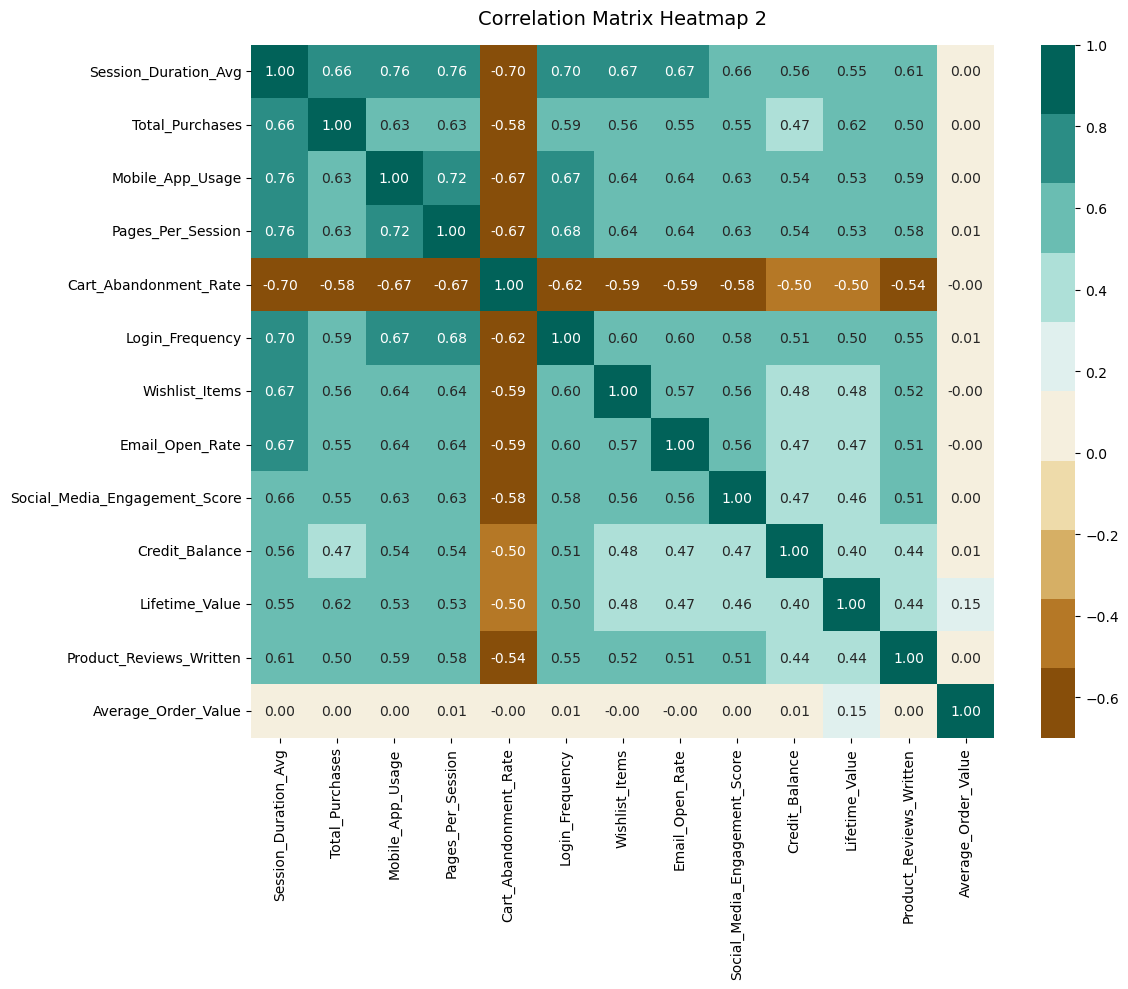

In [29]:
feature_names_grouping = feature_importance_df2['Feature'].tolist()

corr_matrix = churn_dataset_encoded[feature_names_grouping].corr()

plt.figure(figsize=(12, 10))
colormap = sns.color_palette("BrBG",10)

sns.heatmap(corr_matrix,annot=True,fmt=".2f",cmap=colormap)

plt.title("Correlation Matrix Heatmap 2", fontsize=14, pad=15)
plt.tight_layout()
plt.show()

### 4.7 Correlation Analysis

The correlation heatmap was used to explore the relationships between the features included in the customer segmentation analysis. This helps identify which customer behaviours tend to move together and whether any features have particularly strong positive or negative relationships.

The strongest positive relationships include session duration and mobile app usage (0.76), session duration and pages per session (0.76), and mobile app usage and pages per session (0.72). This suggests that customers who spend longer on the platform may also browse more pages and make greater use of the mobile app.

Cart abandonment rate has negative correlations with several engagement measures, including session duration (-0.70), mobile app usage (-0.67) and pages per session (-0.67). This suggests that higher cart abandonment tends to be associated with lower engagement across these features.

Average order value has very little correlation with most of the other features in this heatmap, while lifetime value has a relatively weak relationship with many of the engagement measures. This shows that different features may capture different aspects of customer behaviour.

Overall, the heatmap highlights relationships between customer engagement, purchasing behaviour and cart abandonment. However, correlation does not establish cause and effect, and it does not tell us on its own which features are most useful for predicting churn. These findings provide additional context for the feature-importance results and the predictive modelling explored later in the project.

When it comes to grouping, based on the initial KMeans Clustering results, the important features are:

**Supporting features (highest correlation):**
- Session_Duration_Avg
- Total_Purchases
- Mobile_App_Usage
- Pages_Per_Session
- Cart_Abandonment_Rate
- Login_Frequency
- Wishlist_Items
- Email_Open_Rate

**Probably helpful (moderate correlation)**
- Lifetime_Value
- Social_Media_Engagement_Score
- Credit_Balance
- Product_Reviews_Written

**Droppable (very low correlation):**
- Average_Order_Value

In [30]:
print(churn_dataset.columns)

Index(['Age', 'Gender', 'Country', 'City', 'Membership_Years',
       'Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session',
       'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases',
       'Average_Order_Value', 'Days_Since_Last_Purchase',
       'Discount_Usage_Rate', 'Returns_Rate', 'Email_Open_Rate',
       'Customer_Service_Calls', 'Product_Reviews_Written',
       'Social_Media_Engagement_Score', 'Mobile_App_Usage',
       'Payment_Method_Diversity', 'Lifetime_Value', 'Credit_Balance',
       'Churned', 'Signup_Quarter'],
      dtype='object')


In [31]:
columns_to_keep = ['Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 
                   'Total_Purchases', 'Email_Open_Rate', 'Mobile_App_Usage', 'Lifetime_Value', 'Credit_Balance', 'Churned']
churn_df = churn_dataset[columns_to_keep]
churn_df.to_csv('churn_data_ready.csv', index=False)

In [32]:
churn_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Login_Frequency        50000 non-null  float64
 1   Session_Duration_Avg   46601 non-null  float64
 2   Pages_Per_Session      47000 non-null  float64
 3   Cart_Abandonment_Rate  50000 non-null  float64
 4   Wishlist_Items         46000 non-null  float64
 5   Total_Purchases        50000 non-null  float64
 6   Email_Open_Rate        47472 non-null  float64
 7   Mobile_App_Usage       45000 non-null  float64
 8   Lifetime_Value         50000 non-null  float64
 9   Credit_Balance         44500 non-null  float64
 10  Churned                50000 non-null  int64  
dtypes: float64(10), int64(1)
memory usage: 4.2 MB


### 4.8 Final Feature Selection

After reviewing the feature-importance results and correlation heatmap, a final set of features was selected for the churn prediction analysis. The selection considered which variables helped distinguish between customer groups, how the features related to each other, and whether they were relevant to customer behaviour.

The final dataset retained 10 customer features: login frequency, average session duration, pages per session, cart abandonment rate, wishlist items, total purchases, email open rate, mobile app usage, lifetime value and credit balance. The `Churned` variable was retained as the target used to train the prediction models.

Average order value was excluded from the final feature set because it showed very little correlation with the other selected features in the heatmap. The aim of this process was to focus the subsequent modelling on a smaller group of variables that captured useful aspects of customer engagement, purchasing behaviour and value.

## 5. Customer Economics

Understanding customer behaviour is important, but it is also useful to consider the financial impact of acquiring and retaining customers. For Le Shoppe, customer acquisition cost helps show how much is spent bringing in new customers, while lifetime value provides an indication of the revenue associated with a customer over time.

This section explores customer acquisition cost across marketing channels and compares these costs with the average customer lifetime value. The aim is to provide additional business context for retention decisions and help understand the potential value of keeping existing customers.

### 5.1 Customer Acquisition Cost

Customer acquisition cost (CAC) measures how much a business spends to gain new customers. For Le Shoppe, this is useful because customers who leave may need to be replaced through further marketing activity. Comparing acquisition costs across channels can help the business understand how much it spends to attract new customers.

In [33]:
customer_acquistion_cost_df = pd.read_csv('customer_acquisition_cost_dataset.csv')
customer_acquistion_cost_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Customer_ID        500 non-null    object 
 1   Marketing_Channel  500 non-null    object 
 2   Marketing_Spend    500 non-null    float64
 3   New_Customers      500 non-null    int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 15.8+ KB


In [34]:
channel_data = customer_acquistion_cost_df.groupby('Marketing_Channel')[['Marketing_Spend','New_Customers']].sum()
channel_data['CAC'] = channel_data['Marketing_Spend'] / channel_data['New_Customers']
channel_data.reset_index(inplace=True)
average_cac = channel_data['CAC'].mean()
cac_metrics1 = {"Metric": ["Average CAC - all channels"] + [f" - {channel}" for channel in channel_data['Marketing_Channel']],
                "Value": [average_cac] + channel_data['CAC'].tolist()}
print(f"The average cost to acquire a new customer across all marketing channels is ${average_cac:.2f}")

The average cost to acquire a new customer across all marketing channels is $103.04


The results show an average acquisition cost of 103.04 NZD per customer across the marketing channels included in the dataset. Online Ads had the lowest reported acquisition cost at 99.78 NZD, while Email Marketing had the highest at 107.18 NZD.

Although the difference between channels is relatively small, these results give Le Shoppe a starting point for comparing acquisition costs. CAC should also be considered alongside customer value and the longer-term performance of customers acquired through each channel.

### 5.2 Return on Investment

Customer acquisition cost shows how much Le Shoppe spends to gain new customers, but it is also useful to compare this cost with the value those customers may generate over time.

For this analysis, the average customer Lifetime Value (LTV) is used as an estimate of customer revenue. This is compared with the customer acquisition cost for each marketing channel to understand how customer value relates to the initial cost of acquiring them.

The ROI calculation used in the analysis is:

ROI (%) = ((Customer Revenue - CAC) / CAC) × 100

In [35]:
average_revenue_per_customer = churn_dataset['Lifetime_Value'].mean()
print(f"The average revenue per customer is ${average_revenue_per_customer:.2f}")

The average revenue per customer is $1440.63


In [36]:
channel_data['ROI'] = ((average_revenue_per_customer - channel_data['CAC']) / channel_data['CAC']) * 100
cac_metrics2 = {"Metric": ["Return on Investment - all channels"] + [f" - {channel}" for channel in channel_data['Marketing_Channel']] + ["LTV:CAC Ratio"], 
                "Value": [channel_data['ROI'].mean()] + channel_data['ROI'].tolist() + [get_ratio(average_revenue_per_customer, channel_data['CAC'].iloc[0])]}

In [37]:
channel_data.style.set_caption('Customer Acquisition Cost by Marketing Channel').format(precision=2)

,Marketing_Channel,Marketing_Spend,New_Customers,CAC,ROI
0,Email Marketing,384034.64,3583,107.18,1244.09
1,Online Ads,388747.87,3896,99.78,1343.78
2,Referral,391420.51,3904,100.26,1336.87
3,Social Media,383160.25,3652,104.92,1273.10


In [38]:
print(f"The LTV:CAC ratio is {get_ratio(average_revenue_per_customer, channel_data['CAC'].iloc[0])}")

The LTV:CAC ratio is 13.4:1


In [39]:
churned_customers = (churn_dataset['Churned'] == 1).sum()

In [40]:
total_customers = len(churn_dataset)
churn_rate = churned_customers / total_customers
print(f"The overall churn rate is {churn_rate:.2%}")

The overall churn rate is 28.90%


The LTV:CAC ratio was approximately 13.4:1, meaning the average customer Lifetime Value was around 13.4 times the average acquisition cost. This provides another way to compare the estimated value of customers with the cost of bringing them into the business.

The overall churn rate across the dataset was 28.90%. This means that approximately 29% of the customers in the dataset were recorded as churned. For Le Shoppe, this highlights the importance of understanding which customers may be at risk of leaving and where retention efforts could be focused.

Taken together, the customer economics results provide useful context for the churn analysis. Although the estimated lifetime value is substantially higher than acquisition cost, the churn rate suggests there is still an opportunity to investigate customer behaviour and improve retention. These figures should be interpreted as estimates based on the available datasets rather than a complete measure of business profitability.

## 6. Model Experimentation

After exploring customer behaviour and the financial aspects of customer retention, the next step was to develop machine learning models to identify customers who may be at risk of churning.

Different algorithms were tested and compared to see how effectively they could identify churned customers. This section begins with CatBoost, including an initial model, risk-tier exploration and hyperparameter tuning. The results are then used to evaluate the model before moving on to the other algorithms.

Throughout this process, the focus is on more than overall accuracy. Identifying customers who have churned is particularly important for Le Shoppe, as missing these customers could mean losing opportunities to improve retention.

### 6.1 Initial CatBoost Model

CatBoost was selected as the first modelling approach because it uses gradient boosting to build a predictive model from decision trees. The initial model provides a baseline against which later tuning experiments can be compared.

The dataset was split into training and testing sets, with 80% of the data used for training and 20% held out for testing. The initial CatBoost model used 100 iterations and a learning rate of 0.1. Its predicted churn probabilities were then used for further evaluation and exploration of customer risk tiers.

In [41]:
y = churn_df['Churned']
X = churn_df.drop('Churned', axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_cb1 = CatBoostClassifier(iterations=100, learning_rate=0.1, verbose=0)
model_cb1.fit(X_train, y_train)

y_proba = model_cb1.predict_proba(X_test)[:, 1]

In [42]:
low_risk_thresholds = [0.3, 0.325, 0.35, 0.375, 0.4, 0.425, 0.45, 0.475, 0.5]
med_risk_thresholds = [0.4, 0.45, 0.5, 0.525, 0.55, 0.575, 0.6, 0.625, 0.65]
low_ta, med_ta = determine_best_risk_thresholds(y_proba, y_test, low_risk_thresholds, med_risk_thresholds)

Best Results
----------------------------------------------
Low threshold: 0.5
Medium threshold: 0.65
Accuracy: 0.7486
                Low      High
                             
Precision  0.814628  0.826454
Recall     0.926367  0.306969
F1 Score   0.866912  0.447663


The initial CatBoost model was used as a baseline for exploring customer churn prediction. After training the model, predicted probabilities were used to test different thresholds for assigning customers to low- and high-risk groups.

The best-performing threshold combination in this experiment was a low-risk threshold of 0.50 and a medium-risk threshold of 0.65. The model achieved an accuracy of 74.86%.

The precision and recall results show a difference between the two risk groups. The low-risk group had a precision of approximately 81.46% and a recall of 92.64%, while the high-risk group had a precision of approximately 82.65% and a recall of 30.70%. This indicates that the model identified the low-risk group more consistently, while recall for the high-risk group was considerably lower.

This is important for Le Shoppe because a low recall for the high-risk group means some customers who have churned may not be identified by this approach. These results provide a baseline for comparison as the model's hyperparameters and risk thresholds are explored further.

### 6.2 Hyperparameter Tuning

After establishing the baseline model, hyperparameter tuning was used to explore whether different CatBoost settings could improve predictive performance. Hyperparameters control how the model learns from the training data, including the number of iterations, learning rate and tree depth.

The tuning process evaluates different settings and compares their results against the baseline model. This helps identify a configuration that better balances the ability to identify churned customers with overall model performance.

In [43]:
y = churn_df['Churned']
X = churn_df.drop('Churned', axis=1)

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model_cb2 = CatBoostClassifier(logging_level='Silent')

In [44]:
param_grid = {'depth': [3,4,5,6]}

grid_search_result = model_cb2.grid_search(
    param_grid,
    X=X_train, y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result['params'] )

Best parameters found: {'depth': 6}


The first tuning experiment identified a tree depth of 6 as the best setting from the values tested. The search compared depths of 3, 4, 5 and 6 using three-fold cross-validation.

This gives us a starting point for the next stage of tuning. However, finding the best depth within this search does not necessarily mean the overall model has improved on the baseline. Further experiments are needed to explore other hyperparameters and assess the final model's performance.

In [45]:
model_cb3 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
}

grid_search_result2 = model_cb3.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result2['params'] )

Best parameters found: {'depth': 5, 'iterations': 700}


In [46]:
model_cb4 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [580, 585, 590, 595, 600, 605, 610, 615, 620]
}

grid_search_result3 = model_cb4.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result3['params'] )

Best parameters found: {'depth': 5, 'iterations': 620}


In [47]:
model_cb5 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [550, 565, 560, 565, 570, 575, 580]
}

grid_search_result4 = model_cb5.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result4['params'] )

Best parameters found: {'depth': 5, 'iterations': 550}


In [48]:
model_cb6 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [561, 562, 563, 564, 565, 566, 567, 568, 569]
}

grid_search_result5 = model_cb6.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result5['params'] )

Best parameters found: {'depth': 5, 'iterations': 561}


In [49]:
model_cb7 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [551, 552, 553, 554, 555, 556, 557, 558, 559, 560, 561, 562]
}

grid_search_result6 = model_cb7.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result6['params'] )

Best parameters found: {'depth': 5, 'iterations': 551}


The number of iterations was tuned through a series of grid searches, progressively narrowing the range of values tested. The tree depth was held constant at 5 during these experiments, allowing the focus to remain on identifying a suitable number of iterations.

The search results moved from 700 iterations in the initial search to 620, 580, 565, 561 and finally 551 iterations. This process allowed the search to focus on increasingly specific ranges based on the results of the previous experiments.

The final search identified 551 iterations as the best value among those tested in this stage. This setting was carried forward as a candidate for further tuning. It does not necessarily mean that this is the best overall model configuration, as other hyperparameters still need to be considered.

### Learning Rate

After exploring the number of iterations, the next tuning stage focused on the learning rate. This controls how much each boosting step contributes to the model, affecting how quickly it learns from the training data.

The first grid search tested learning rates between 0.1 and 0.7 and identified 0.2 as the best value. A second search then tested a narrower range of values around this result and identified 0.15 as the best setting.

Throughout these experiments, tree depth was held at 5 and the number of iterations was fixed at 554. The learning rate of 0.15 was therefore selected as the best value among those tested in this stage. Further tuning was still required to explore other model settings before settling on the final configuration.

In [50]:
model_cb8 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [554],
    'learning_rate': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
}

grid_search_result7 = model_cb8.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result7['params'] )

Best parameters found: {'depth': 5, 'learning_rate': 0.2, 'iterations': 554}


In [51]:
model_cb9 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [554],
    'learning_rate': [0.125, 0.15, 0.175, 0.2, 0.225, 0.25]
}

grid_search_result8 = model_cb9.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result8['params'] )

Best parameters found: {'depth': 5, 'learning_rate': 0.15, 'iterations': 554}


#### Early Stopping Rounds

The next experiment explored early stopping rounds, which control how long the model continues training without improvement before stopping. This can help avoid unnecessary training once performance stops improving.

The search compared several early-stopping settings while keeping the tree depth at 5, the number of iterations at 554 and the learning rate at 0.15. The best result from this search used 10 early-stopping rounds.

This setting was carried forward into the next tuning stage. It represents the best value among those tested here, rather than confirmation that the overall model has reached its best possible performance.

In [52]:
model_cb10 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [554],
    'learning_rate': [0.15],
    'early_stopping_rounds': [False, 2, 5, 7, 10, 12, 15]
}

grid_search_result9 = model_cb10.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result9['params'] )

Best parameters found: {'depth': 5, 'od_wait': 5, 'learning_rate': 0.15, 'iterations': 554}


### Grow Policy

The next experiment explored the tree growth policy used by CatBoost. This setting controls how the decision trees are built and can influence the complexity of the patterns the model learns.

Three policies were compared: SymmetricTree, Depthwise and Lossguide. The other selected settings were kept fixed so that the experiment could focus on the effect of changing the growth policy.

The best-performing policy from this search was then carried forward to the next tuning stage. This result represents the best option among the policies tested, rather than a guarantee that it will produce the best overall model.

In [53]:
model_cb11 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [554],
    'learning_rate': [0.15],
    'early_stopping_rounds': [10],
    'grow_policy': ['SymmetricTree','Depthwise','Lossguide']
}

grid_search_result10 = model_cb11.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result10['params'] )

Best parameters found: {'grow_policy': 'Lossguide', 'depth': 5, 'od_wait': 10, 'learning_rate': 0.15, 'iterations': 554}


#### Regularisation

The next experiment explored regularisation settings to see how they affected the CatBoost model. Regularisation helps control model complexity and can reduce the risk of overfitting, where a model learns patterns in the training data that do not generalise well to unseen data.

The search tested different values for L2 leaf regularisation, random strength and bagging temperature while keeping the previously selected parameters fixed. The best combination from this search used an L2 leaf regularisation value of 10, random strength of 1 and bagging temperature of 0.

These values were carried forward to the final grid search, where the selected hyperparameters were checked together.

In [54]:
model_cb12 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'depth': [5],
    'iterations': [554],
    'learning_rate': [0.15],
    'early_stopping_rounds': [10],
    'grow_policy': ['SymmetricTree'],
    'l2_leaf_reg': [0, 1, 3, 5, 7, 9, 10, 12, 15],
    'random_strength': [0, 0.5, 1, 1.5, 2],
    'bagging_temperature': [0, 0.1, 0.5, 0.7, 1]
}

grid_search_result11 = model_cb12.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result11['params'] )

Best parameters found: {'random_strength': 0, 'od_wait': 10, 'iterations': 554, 'bagging_temperature': 0, 'l2_leaf_reg': 9, 'grow_policy': 'SymmetricTree', 'depth': 5, 'learning_rate': 0.15}


In [55]:
model_cb13 = CatBoostClassifier(logging_level='Silent')

param_grid = {
    'learning_rate': [0.15, 0.2],
    'iterations': [554, 558, 561],
    'depth': [4, 5, 6],
    'early_stopping_rounds': [False, 10],
    'l2_leaf_reg': [0, 5, 10],
    'grow_policy': ['SymmetricTree','Depthwise','Lossguide'],
    'random_strength': [0, 1],
    'bagging_temperature': [0, 1],
    'logging_level': ['Silent']
}

grid_search_result12 = model_cb13.grid_search(
    param_grid,
    X=X_train,
    y=y_train,
    cv=3,
    partition_random_seed = 42,
    plot=False,
    verbose=False
)

print("Best parameters found:" , grid_search_result12['params'] )

Best parameters found: {'random_strength': 0, 'od_wait': 10, 'iterations': 554, 'logging_level': 'Silent', 'bagging_temperature': 0, 'l2_leaf_reg': 5, 'grow_policy': 'SymmetricTree', 'depth': 5, 'learning_rate': 0.2}


#### Final Grid Search

The final grid search tested combinations of the main hyperparameters together to identify the best configuration from the values included in the search.

The best combination returned a tree depth of 5, 554 iterations and a learning rate of 0.2. It also selected 10 for the early-stopping wait, an L2 leaf regularisation value of 5, the SymmetricTree growth policy, random strength of 0 and bagging temperature of 0.

The results show that the best combination can differ from the settings selected during individual tuning experiments. These are the best parameters found within the tested search space, rather than proof that no better configuration exists. The model's final evaluation results will be needed to assess how well it identifies customers who churn.

### 6.3 Evaluating the Tuned CatBoost Model

After completing the hyperparameter tuning experiments, the next step was to evaluate the CatBoost model's performance. This section examines how well the model distinguishes between customers who churn and those who remain, using the AUC-ROC score and ROC curve.

In [56]:
model_cb14 = CatBoostClassifier(logging_level='Silent',
    iterations = 554,
    learning_rate = 0.15,
    depth = 4,
    grow_policy = 'SymmetricTree',
    bagging_temperature = 0,
    random_strength = 0,
    early_stopping_rounds = 10)

model_cb14.fit(
    X_train, y_train,
    eval_set=(X_test, y_test),
    verbose=False
)

y_pred_14 = model_cb14.predict(X_test)

In [57]:
y_pred_proba14 = model_cb14.predict_proba(X_test)[:, 1]
auc_score_cb14 = roc_auc_score(y_test, y_pred_proba14)
print(f"CatBoost AUC-ROC: {auc_score_cb14:.4f}")

CatBoost AUC-ROC: 0.8042


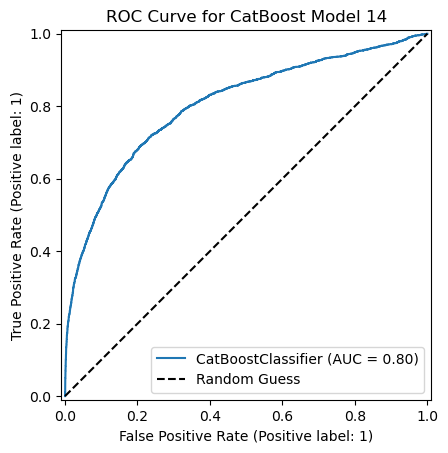

In [58]:
RocCurveDisplay.from_estimator(model_cb14, X_test, y_test)
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.title('ROC Curve for CatBoost Model 14'); plt.legend(); plt.show()

### 6.4 Random Forest

Random Forest was evaluated as another approach to predicting customer churn. It combines predictions from multiple decision trees to identify patterns in customer behaviour.

The dataset was split into training and testing sets, and missing values were imputed using the median values from the training data. The model was then trained on the prepared data and used to predict churn probabilities for the test set.

The results were evaluated using a classification report, confusion matrix and customer risk categories. This helps assess not only overall model performance, but also how well the model identifies customers who actually churn.

In [59]:
y = churn_df['Churned']
X = churn_df.drop('Churned', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [60]:
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

In [61]:
model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

In [62]:
low_risk_thresholds = [0.3, 0.325, 0.35, 0.375, 0.4, 0.425, 0.45, 0.475, 0.5, 0.525, 0.5]
med_risk_thresholds = [0.4, 0.45, 0.5, 0.525, 0.55, 0.575, 0.6, 0.625, 0.65, 0.675, 0.7]

In [63]:
report = classification_report(y_test, y_pred)
print(report)
low_t, med_t = determine_best_risk_thresholds(y_proba, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.92      0.86      7130
           1       0.70      0.48      0.57      2870

    accuracy                           0.79     10000
   macro avg       0.76      0.70      0.71     10000
weighted avg       0.78      0.79      0.78     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7741
                Low      High
                             
Precision  0.807052  0.762267
Recall     0.930996  0.384321
F1 Score   0.864604  0.511003
[[6546  584]
 [1506 1364]]


In [64]:
risk_counts = Counter(assign_risk_tier(p, low_t, med_t) for p in y_proba)

print("Low:", risk_counts['Low']) 
print("Medium:", risk_counts['Med']) 
print("High:", risk_counts['High'])

Low: 8225
Medium: 328
High: 1447


The Random Forest model achieved an overall accuracy of approximately **77.4%** using the selected classification thresholds. The classification report shows that the model identified customers who did not churn more successfully than customers who did churn.

For customers who churned (class 1), the model achieved a precision of **70%** and a recall of **48%**. This means it identified approximately 48% of actual churners, while missing a substantial proportion of customers who eventually churned. This is important for Le Shoppe because missed churners represent customers who may not receive timely retention support.

The model assigned **8,225 customers to the low-risk group, 328 to the medium-risk group, and 1,447 to the high-risk group**. These categories provide a potential way to prioritise retention activity, although the thresholds should be validated before being used operationally.

Overall, the Random Forest model provides a useful baseline, but its ability to identify customers who churn is limited at the current classification threshold. Later models will be compared to determine whether they offer a better balance between identifying churners and overall predictive performance.

## Hyperparameter Tuning

Hyperparameter tuning was used to explore whether adjusting the Random Forest model's settings could improve its ability to identify customers who churn. The search tested different combinations of tree counts, tree depth, minimum sample requirements, feature selection strategies, and class weighting.

Grid search with three-fold cross-validation was used to compare the candidate configurations using the F1 score. This provided a structured way to evaluate different settings before assessing the selected configuration on the test data.

In [65]:
model_rf1 = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [300, 600],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

grid_search_rf = GridSearchCV(
    estimator=model_rf1,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_rf.fit(X_train, y_train)
print(grid_search_rf.best_params_)
print(grid_search_rf.best_score_)
model_rf_best = grid_search_rf.best_estimator_

Fitting 3 folds for each of 96 candidates, totalling 288 fits
{'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 600}
0.6215086849518671


In [66]:
y_pred2 = grid_search_rf.predict(X_test)
y_proba2 = grid_search_rf.predict_proba(X_test)[:, 1]
report2 = classification_report(y_test, y_pred2)
print(report2)
low_t, med_t = determine_best_risk_thresholds(y_proba2, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred2))

              precision    recall  f1-score   support

           0       0.86      0.79      0.83      7130
           1       0.57      0.69      0.62      2870

    accuracy                           0.76     10000
   macro avg       0.72      0.74      0.72     10000
weighted avg       0.78      0.76      0.77     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7513
                Low      High
                             
Precision  0.855226  0.626189
Recall     0.813604  0.596516
F1 Score   0.833896  0.610992
[[5641 1489]
 [ 903 1967]]


In [67]:
risk_counts = Counter(assign_risk_tier(p, low_t, med_t) for p in y_proba2)

print("Low:", risk_counts['Low']) 
print("Medium:", risk_counts['Med']) 
print("High:", risk_counts['High'])

Low: 6783
Medium: 483
High: 2734


In [68]:
X3 = churn_df.drop(['Churned', 'Login_Frequency', 'Mobile_App_Usage', 'Wishlist_Items', 'Pages_Per_Session'], axis=1)

X_train3, X_test3, y_train3, y_test3 = train_test_split(X3, y, test_size=0.2, random_state=42)

X_train3 = imputer.fit_transform(X_train3)
X_test3 = imputer.transform(X_test3)

In [69]:
X3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Session_Duration_Avg   46601 non-null  float64
 1   Cart_Abandonment_Rate  50000 non-null  float64
 2   Total_Purchases        50000 non-null  float64
 3   Email_Open_Rate        47472 non-null  float64
 4   Lifetime_Value         50000 non-null  float64
 5   Credit_Balance         44500 non-null  float64
dtypes: float64(6)
memory usage: 2.3 MB


In [70]:
model = RandomForestClassifier(
    n_estimators=500,
    random_state=42
)

model.fit(X_train3, y_train3)

y_proba3 = model.predict_proba(X_test3)[:, 1]
y_pred3 = model.predict(X_test3)

In [71]:
report3 = classification_report(y_test3, y_pred3)
print(report3)
low_t3, med_t3 = determine_best_risk_thresholds(y_proba3, y_test3, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test3, y_pred3))

              precision    recall  f1-score   support

           0       0.81      0.91      0.86      7130
           1       0.68      0.46      0.55      2870

    accuracy                           0.78     10000
   macro avg       0.74      0.69      0.70     10000
weighted avg       0.77      0.78      0.77     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7653
                Low      High
                             
Precision  0.800534  0.725840
Recall     0.924825  0.368990
F1 Score   0.858203  0.489258
[[6513  617]
 [1557 1313]]


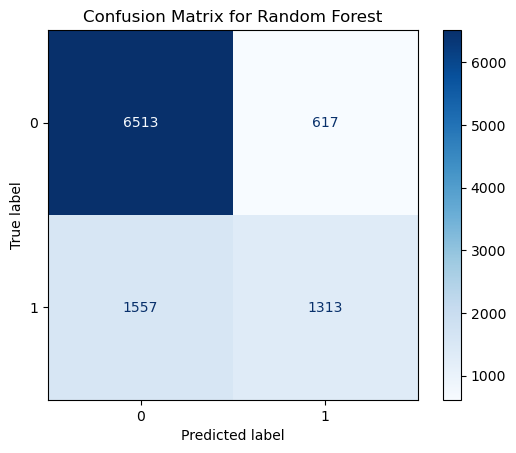

In [72]:
cm = confusion_matrix(y_test3, y_pred3, labels=model.classes_)
cm_disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
cm_disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix for Random Forest")
plt.show()

The Random Forest grid search selected a configuration with 600 trees, a maximum depth of 10, and balanced class weights. The search compared 96 parameter combinations using three-fold cross-validation, with F1 score used to evaluate each configuration.

On the test set, the tuned model achieved approximately 76% accuracy and 69% recall for customers who churned. Recall is particularly relevant to Le Shoppe because it measures how many actual churn cases the model successfully identifies. However, the results also show that identifying at-risk customers remains challenging, so the model's predictions should support retention decisions rather than be treated as certain outcomes.

### XGBoost Model

XGBoost was evaluated as another approach to predicting customer churn. It uses gradient boosting to combine decision trees, with each successive tree helping to improve the model's predictions.

The model was trained using the existing training data and evaluated on the test set. Its predicted churn probabilities were used to assess classification performance and explore how effectively the model could identify customers who may leave Le Shoppe.

The results were compared using precision, recall, F1 score and overall accuracy. Particular attention was given to recall for the churn class, as identifying customers who may leave is important when planning targeted retention activities.

In [73]:
xgb_model = XGBClassifier(random_state=42)

xgb_model.fit(X_train, y_train)

y_proba4 = xgb_model.predict_proba(X_test)[:, 1]
y_pred4 = xgb_model.predict(X_test)

In [74]:
report4 = classification_report(y_test, y_pred4)
print(report4)
low_t4, med_t4 = determine_best_risk_thresholds(y_proba4, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred4))

              precision    recall  f1-score   support

           0       0.81      0.91      0.86      7130
           1       0.68      0.47      0.56      2870

    accuracy                           0.78     10000
   macro avg       0.74      0.69      0.71     10000
weighted avg       0.77      0.78      0.77     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7708
                Low      High
                             
Precision  0.805297  0.720152
Recall     0.921178  0.397213
F1 Score   0.859348  0.512014
[[6482  648]
 [1508 1362]]


The XGBoost model achieved approximately 74% accuracy. However, recall for customers who churned was around 47%, meaning the model identified fewer than half of the actual churn cases at the evaluated classification threshold.

Although overall accuracy provides a useful measure of performance, it does not fully reflect how well the model identifies customers who may leave. For Le Shoppe, this limitation matters because customers who are not identified as at risk may miss opportunities for retention outreach. The model therefore needs to be considered alongside other approaches, particularly those that achieve stronger recall for the churn class.

### Hyperparameter Tuning

After establishing the initial XGBoost model, hyperparameter tuning was used to explore whether alternative settings could improve churn prediction performance. The search tested different combinations of the number of trees, tree depth, learning rate, subsampling, column sampling and minimum child weight.

Grid search with three-fold cross-validation compared the candidate configurations using the F1 score. The best-performing configuration from the search was then evaluated on the test set to assess its ability to identify customers who churned.

In [75]:
param_grid = {
    'n_estimators': [100, 300, 600],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'min_child_weight': [1, 5]
}

grid_search_xgb = GridSearchCV(
    estimator=xgb_model,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_xgb.fit(X_train, y_train)
print(grid_search_xgb.best_params_)
print(grid_search_xgb.best_score_)
model_xgb_best = grid_search_xgb.best_estimator_

Fitting 3 folds for each of 216 candidates, totalling 648 fits
{'colsample_bytree': 0.8, 'learning_rate': 0.2, 'max_depth': 3, 'min_child_weight': 5, 'n_estimators': 100, 'subsample': 0.8}
0.564010515510966


In [76]:
y_pred5 = model_xgb_best.predict(X_test)
y_proba5 = model_xgb_best.predict_proba(X_test)[:, 1]
report5 = classification_report(y_test, y_pred5)
print(report5)
low_t5, med_t5 = determine_best_risk_thresholds(y_proba5, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred5))

              precision    recall  f1-score   support

           0       0.81      0.92      0.86      7130
           1       0.70      0.47      0.56      2870

    accuracy                           0.79     10000
   macro avg       0.76      0.70      0.71     10000
weighted avg       0.78      0.79      0.78     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7766
                Low      High
                             
Precision  0.806420  0.769604
Recall     0.933661  0.386411
F1 Score   0.865388  0.514498
[[6553  577]
 [1514 1356]]


The grid search selected an XGBoost configuration with 100 trees, a maximum depth of 3, a learning rate of 0.2, and subsampling and column-sampling values of 0.8. The minimum child weight was set to 5. These parameters produced the best cross-validation score among the combinations tested.

The model achieved approximately 78% accuracy using the selected risk thresholds. However, the classification report shows that recall for the churn class was approximately 47% at the default classification threshold. This highlights why accuracy alone is not sufficient when evaluating churn prediction. Le Shoppe needs to consider how many customers at risk are identified, alongside the number of customers incorrectly flagged, when deciding how the model could support retention outreach.

In [77]:
for threshold in [0.2, 0.3, 0.4, 0.5]:
    y_pred = (y_proba5 >= threshold).astype(int)

    print(
        f"Threshold {threshold}:",
        f"Precision={precision_score(y_test, y_pred):.3f}",
        f"Recall={recall_score(y_test, y_pred):.3f}",
        f"F1={f1_score(y_test, y_pred):.3f}"
    )

Threshold 0.2: Precision=0.475 Recall=0.809 F1=0.599
Threshold 0.3: Precision=0.546 Recall=0.716 F1=0.620
Threshold 0.4: Precision=0.627 Recall=0.595 F1=0.611
Threshold 0.5: Precision=0.702 Recall=0.472 F1=0.565


### Evaluating Classification Thresholds

The tuned XGBoost model was evaluated at four probability thresholds to understand how the classification cut-off affects precision, recall and the F1-score.

A lower threshold identifies more customers as potential churners, increasing recall but also producing more false positives. A higher threshold reduces the number of customers flagged, but may miss more customers who eventually churn.

The results show that a threshold of 0.2 achieved the highest recall at 80.9%, while a threshold of 0.3 produced the highest F1-score of 0.620. At a threshold of 0.5, precision increased to 70.2%, but recall fell to 47.2%.

This demonstrates the trade-off between identifying as many at-risk customers as possible and limiting unnecessary retention outreach. Le Shoppe should select a threshold based on its campaign capacity and the relative costs of missed churners versus contacting customers who would have stayed.

### 6.6 LightGBM

LightGBM was evaluated as another gradient-boosting approach to predicting customer churn. It builds decision trees sequentially, with each stage aiming to improve on errors made by previous trees.

The model was trained using the existing training and testing split. Its performance was assessed using a classification report, confusion matrix and customer risk thresholds, allowing comparison of its ability to identify customers who may churn.

In [78]:
lgb_model = LGBMClassifier(random_state=42)

lgb_model.fit(X_train, y_train)

y_proba5 = lgb_model.predict_proba(X_test)[:, 1]
y_pred5 = lgb_model.predict(X_test)

[LightGBM] [Info] Number of positive: 11580, number of negative: 28420
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001183 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1900
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.289500 -> initscore=-0.897814
[LightGBM] [Info] Start training from score -0.897814


In [79]:
report5 = classification_report(y_test, y_pred5)
print(report5)
low_t5, med_t5 = determine_best_risk_thresholds(y_proba5, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred5))

              precision    recall  f1-score   support

           0       0.81      0.92      0.86      7130
           1       0.70      0.47      0.57      2870

    accuracy                           0.79     10000
   macro avg       0.76      0.70      0.71     10000
weighted avg       0.78      0.79      0.78     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7768
                Low      High
                             
Precision  0.805677  0.760811
Recall     0.931557  0.392334
F1 Score   0.864056  0.517701
[[6561  569]
 [1512 1358]]


The LightGBM model achieved approximately 79% accuracy. However, the classification report shows a recall of approximately 47% for customers who churned at the default classification threshold. This means the model identified fewer than half of the actual churn cases using that threshold.

The threshold analysis provides a different perspective by exploring how changing the probability cut-offs affects customer risk classification. Although overall accuracy is useful, Le Shoppe should also consider how many at-risk customers are identified and how many customers are incorrectly flagged before deciding whether the model is suitable for retention campaigns.

### Hyperparameter Tuning

Hyperparameter tuning was used to investigate whether adjusting LightGBM's settings could improve its ability to identify customers who churn. The grid search tested different combinations of the number of trees, maximum tree depth, learning rate, number of leaves, minimum child samples and column sampling.

Three-fold cross-validation and the F1-score were used to compare the candidate configurations. The best-performing configuration was then evaluated on the test data to assess its classification performance.

In [80]:
param_grid = {
    'n_estimators': [100, 300, 600],
    'max_depth': [-1, 3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'num_leaves': [15, 31, 63],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

grid_search_lgb = GridSearchCV(
    estimator=lgb_model,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

grid_search_lgb.fit(X_train, y_train)
print(grid_search_lgb.best_params_)
print(grid_search_lgb.best_score_)
model_lgb_best = grid_search_lgb.best_estimator_

Fitting 3 folds for each of 432 candidates, totalling 1296 fits
[LightGBM] [Info] Number of positive: 11580, number of negative: 28420
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001040 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1900
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.289500 -> initscore=-0.897814
[LightGBM] [Info] Start training from score -0.897814
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gai

In [81]:
y_pred6 = grid_search_lgb.predict(X_test)
y_proba6 = grid_search_lgb.predict_proba(X_test)[:, 1]
report6 = classification_report(y_test, y_pred6)
print(report6)
low_t6, med_t6 = determine_best_risk_thresholds(y_proba6, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred6))

              precision    recall  f1-score   support

           0       0.81      0.92      0.86      7130
           1       0.71      0.47      0.57      2870

    accuracy                           0.79     10000
   macro avg       0.76      0.70      0.72     10000
weighted avg       0.78      0.79      0.78     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7763
                Low      High
                             
Precision  0.806843  0.762329
Recall     0.932679  0.387805
F1 Score   0.865209  0.514088
[[6578  552]
 [1511 1359]]


In [82]:
for threshold in [0.2, 0.3, 0.4, 0.5]:
    y_pred = (y_proba6 >= threshold).astype(int)

    print(
        f"Threshold {threshold}:",
        f"Precision={precision_score(y_test, y_pred):.3f}",
        f"Recall={recall_score(y_test, y_pred):.3f}",
        f"F1={f1_score(y_test, y_pred):.3f}"
    )

Threshold 0.2: Precision=0.477 Recall=0.802 F1=0.598
Threshold 0.3: Precision=0.553 Recall=0.714 F1=0.623
Threshold 0.4: Precision=0.634 Recall=0.595 F1=0.614
Threshold 0.5: Precision=0.711 Recall=0.474 F1=0.569


In [83]:
model_cb14 = CatBoostClassifier(logging_level='Silent',
    iterations = 554,
    learning_rate = 0.15,
    depth = 4,
    grow_policy = 'SymmetricTree',
    bagging_temperature = 0,
    random_strength = 0,
    early_stopping_rounds = 10)

model_cb14.fit(X_train, y_train)

y_proba7 = model_cb14.predict_proba(X_test)[:, 1]
y_pred7 = model_cb14.predict(X_test)

In [84]:
report7 = classification_report(y_test, y_pred7)
print(report7)
low_t7, med_t7 = determine_best_risk_thresholds(y_proba7, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred7))

              precision    recall  f1-score   support

           0       0.81      0.92      0.86      7130
           1       0.70      0.48      0.57      2870

    accuracy                           0.79     10000
   macro avg       0.76      0.70      0.72     10000
weighted avg       0.78      0.79      0.78     10000

Best Results
----------------------------------------------
Low threshold: 0.525
Medium threshold: 0.575
Accuracy: 0.7739
                Low      High
                             
Precision  0.805988  0.754220
Recall     0.928752  0.389199
F1 Score   0.863026  0.513445
[[6542  588]
 [1496 1374]]


The grid search selected a configuration with 300 estimators, a maximum depth of 5, a learning rate of 0.05, 15 leaves, a minimum child sample setting of 5 and a column-sampling value of 0.8.

The classification report showed approximately 79% accuracy and 47% recall for the churn class at the default classification threshold. This suggests that, despite reasonable overall accuracy, the model missed more than half of the customers who actually churned.

The threshold comparison helps demonstrate how adjusting the probability cut-off changes the balance between precision and recall. These results should be considered alongside the other models rather than relying on accuracy alone to determine the most suitable approach for Le Shoppe.

### Revisiting Random Forest

Following the initial model comparisons, Random Forest was revisited to investigate whether further tuning could improve its ability to identify customers who churn. This experiment expanded the search across the number of trees, tree depth, minimum sample requirements, feature selection and class weighting.

Unlike the earlier tuning experiment, recall was used as the grid-search scoring metric. This prioritises identifying customers who actually churn, although improvements in recall may come at the cost of additional false positives.

In [ ]:
model_rf2 = RandomForestClassifier(random_state=42)

param_grid = {
    'n_estimators': [600, 700, 800],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2'],
    'class_weight': [None, 'balanced']
}

grid_search_rf2 = GridSearchCV(
    estimator=model_rf2,
    param_grid=param_grid,
    cv=3,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

grid_search_rf2.fit(X_train, y_train)
print(grid_search_rf2.best_params_)
print(grid_search_rf2.best_score_)
model_rf_best2 = grid_search_rf2.best_estimator_

Fitting 3 folds for each of 144 candidates, totalling 432 fits


In [ ]:
y_pred8 = grid_search_rf2.predict(X_test)
y_proba8 = grid_search_rf2.predict_proba(X_test)[:, 1]
report8 = classification_report(y_test, y_pred8)
print(report8)
low_t8, med_t8 = determine_best_risk_thresholds(y_proba8, y_test, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test, y_pred8))

The tuned Random Forest model was evaluated using the test dataset, with recall prioritised during hyperparameter selection. The classification report and confusion matrix provide a view of how well the model distinguishes customers who churn from those who remain.

The next experiment investigates whether reducing the number of input features can maintain useful predictive performance while simplifying the model. Comparing the two approaches helps determine whether all available customer attributes are needed for churn prediction.

In [ ]:
churn_df.info()

In [ ]:
X4 = churn_df[['Lifetime_Value', 'Cart_Abandonment_Rate', 'Email_Open_Rate', 'Total_Purchases']]

X_train4, X_test4, y_train4, y_test4 = train_test_split(X4, y, test_size=0.2, random_state=42)

X_train4 = imputer.fit_transform(X_train4)
X_test4 = imputer.transform(X_test4)

In [ ]:
model_rf3 = RandomForestClassifier(
    random_state = 42,
    class_weight = 'balanced', 
    max_depth = 5, 
    max_features = 'sqrt', 
    min_samples_leaf = 1, 
    min_samples_split = 2, 
    n_estimators = 800
)

model_rf3.fit(X_train4, y_train4)

y_pred9 = model_rf3.predict(X_test4)
y_proba9 = model_rf3.predict_proba(X_test4)[:, 1]
report9 = classification_report(y_test4, y_pred9)
print(report9)
low_t9, med_t9 = determine_best_risk_thresholds(y_proba9, y_test4, low_risk_thresholds, med_risk_thresholds)
print(confusion_matrix(y_test4, y_pred9))

The reduced-feature Random Forest model was evaluated to determine whether a smaller set of customer attributes could maintain useful churn prediction performance. The model achieved approximately 73% accuracy, with churn recall of around 72% in the risk-threshold evaluation. This suggests that the model can identify a substantial proportion of customers who churn, although its precision indicates that some customers flagged as at risk may not actually churn.

These results highlight the trade-off between identifying more at-risk customers and limiting unnecessary retention outreach. The reduced-feature model provides a useful comparison with the full-feature Random Forest, helping assess whether simplifying the input data retains enough predictive value for practical use.

### Stacking Model Experiments

Fourteen stacking configurations were evaluated to investigate whether combining different algorithms could improve customer churn prediction. The first experiments compared combinations of Random Forest with XGBoost, CatBoost and LightGBM, using Logistic Regression as the meta-estimator. Further experiments tested alternative meta-estimators, including Ridge Classifier and Random Forest.

The experiments also explored whether reducing the number of input features affected performance. Three feature sets were considered, containing 10, 7 and 4 features respectively. In addition, two classification thresholds were tested for one configuration to examine how changing the threshold affected the identification of customers likely to churn.

Model performance was compared using accuracy, precision, recall and F1-score. Recall was particularly important because it measures the proportion of actual churn customers correctly identified. Precision was also considered to understand how many customers flagged as likely to churn did actually churn.

The results were sorted by recall to help identify configurations that detected a greater proportion of churn customers. However, the highest-recall model would not automatically be the best business choice, as it may also generate more false-positive alerts and increase the workload for Le Shoppe's retention team.

In [ ]:
churn_df = pd.read_csv('churn_data_ready.csv')
y = churn_df['Churned']
X = churn_df.drop('Churned', axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

feature_list1 = ['Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases',
       'Email_Open_Rate', 'Mobile_App_Usage', 'Lifetime_Value', 'Credit_Balance']
feature_list2 = ['Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Total_Purchases', 'Email_Open_Rate', 'Lifetime_Value',
       'Credit_Balance']
feature_list3 = ['Lifetime_Value', 'Cart_Abandonment_Rate', 'Email_Open_Rate', 'Total_Purchases']

In [ ]:
base_estimators1 = [ 
        ('rf', RandomForestClassifier(random_state = 42,
                                  class_weight = 'balanced',
                                  max_depth = 5,
                                  max_features = 'sqrt',
                                  min_samples_leaf = 1,
                                  min_samples_split = 2,
                                  n_estimators = 800)),
        ('xgb', XGBClassifier(random_state = 42,
                                n_estimators=100,
                                learning_rate=0.2,
                                max_depth=3,
                                min_child_weight=5,
                                subsample=0.8,
                                colsample_bytree=0.8))
]

base_estimators2 = [ 
        ('rf', RandomForestClassifier(random_state = 42,
                                  class_weight = 'balanced',
                                  max_depth = 5,
                                  max_features = 'sqrt',
                                  min_samples_leaf = 1,
                                  min_samples_split = 2,
                                  n_estimators = 800)),
        ('cat', CatBoostClassifier(random_state = 42,
                                   logging_level='Silent',
                                   iterations = 554,
                                   learning_rate = 0.15,
                                   depth = 4,
                                   grow_policy = 'SymmetricTree',
                                   bagging_temperature = 0,
                                   random_strength = 0,
                                   early_stopping_rounds = 10))
]

base_estimators3 = [ 
        ('rf', RandomForestClassifier(random_state = 42,
                                  class_weight = 'balanced',
                                  max_depth = 5,
                                  max_features = 'sqrt',
                                  min_samples_leaf = 1,
                                  min_samples_split = 2,
                                  n_estimators = 800)),
        ('lgbm', LGBMClassifier(random_state = 42,
                                    colsample_bytree=1.0,
                                    learning_rate=0.05,
                                    max_depth=5,
                                    n_estimators=300,
                                    num_leaves=15,
                                    subsample=0.8,
                                    verbosity=-1,
                                    logging_level='Silent'))
]

base_estimators4 = [ 
        ('rf', RandomForestClassifier(random_state = 42,
                                  class_weight = 'balanced',
                                  max_depth = 5,
                                  max_features = 'sqrt',
                                  min_samples_leaf = 1,
                                  min_samples_split = 2,
                                  n_estimators = 800)),
        ('cat', CatBoostClassifier(random_state = 42,
                                        logging_level='Silent',
                                        iterations = 554,
                                        learning_rate = 0.15,
                                        depth = 4,
                                        grow_policy = 'SymmetricTree',
                                        bagging_temperature = 0,
                                        random_strength = 0,
                                        early_stopping_rounds = 10)),
        ('lgbm', LGBMClassifier(random_state = 42,
                                    colsample_bytree=1.0,
                                    learning_rate=0.05,
                                    max_depth=5,
                                    n_estimators=300,
                                    num_leaves=15,
                                    subsample=0.8,
                                    verbosity=-1,
                                    logging_level='Silent'))
]

base_estimators5 = [ 
        ('rf', RandomForestClassifier(random_state = 42,
                                  class_weight = 'balanced',
                                  max_depth = 5,
                                  max_features = 'sqrt',
                                  min_samples_leaf = 1,
                                  min_samples_split = 2,
                                  n_estimators = 800)),
        ('cat', CatBoostClassifier(random_state = 42,
                                        logging_level='Silent',
                                        iterations = 554,
                                        learning_rate = 0.15,
                                        depth = 4,
                                        grow_policy = 'SymmetricTree',
                                        bagging_temperature = 0,
                                        random_strength = 0,
                                        early_stopping_rounds = 10)),
        ('xgb', XGBClassifier(random_state = 42,
                                n_estimators=100,
                                learning_rate=0.2,
                                max_depth=3,
                                min_child_weight=5,
                                subsample=0.8,
                                colsample_bytree=0.8))
]

base_estimators6 = [ 
        ('rf', RandomForestClassifier(random_state = 42,
                                  class_weight = 'balanced',
                                  max_depth = 5,
                                  max_features = 'sqrt',
                                  min_samples_leaf = 1,
                                  min_samples_split = 2,
                                  n_estimators = 800)),
        ('lgbm', LGBMClassifier(random_state = 42,
                                    colsample_bytree=1.0,
                                    learning_rate=0.05,
                                    max_depth=5,
                                    n_estimators=300,
                                    num_leaves=15,
                                    subsample=0.8,
                                    verbosity=-1,
                                    logging_level='Silent')),
        ('xgb', XGBClassifier(random_state = 42,
                                n_estimators=100,
                                learning_rate=0.2,
                                max_depth=3,
                                min_child_weight=5,
                                subsample=0.8,
                                colsample_bytree=0.8))
]

base_estimators7 = [ 
        ('cat', CatBoostClassifier(random_state = 42,
                                                logging_level='Silent',
                                                iterations = 554,
                                                learning_rate = 0.15,
                                                depth = 4,
                                                grow_policy = 'SymmetricTree',
                                                bagging_temperature = 0,
                                                random_strength = 0,
                                                early_stopping_rounds = 10))
]

base_estimators8 = [
    ('rf', RandomForestClassifier(random_state = 42,class_weight = 'balanced',max_depth = 5,n_estimators = 800))
]

meta_estimator1 = LogisticRegression()
meta_estimator2 = RidgeClassifier(alpha=1.0, random_state=42)
meta_estimator3 = RandomForestClassifier(random_state = 42,class_weight = 'balanced',max_depth = 5,n_estimators = 800)

In [92]:
stacking_1 = {'Model': 'Stacking 1', 'Base Models': 'RF + XGBoost', 'Meta Estimator': 'Logistic Regression', 'Features': len(feature_list1)}
stacking_model1 = StackingClassifier(estimators=base_estimators1, final_estimator=meta_estimator1, cv=5)
stacking_model1.fit(X_train, y_train)
y_pred10 = stacking_model1.predict(X_test)

stacking_2 = {'Model': 'Stacking 2', 'Base Models': 'RF + CatBoost', 'Meta Estimator': 'Logistic Regression', 'Features': len(feature_list1)}
stacking_model2 = StackingClassifier(estimators=base_estimators2, final_estimator=meta_estimator1, cv=5)
stacking_model2.fit(X_train, y_train)
y_pred11 = stacking_model2.predict(X_test)

stacking_3 = {'Model': 'Stacking 3', 'Base Models': 'RF + LightGBM', 'Meta Estimator': 'Logistic Regression', 'Features': len(feature_list1)}
stacking_model3 = StackingClassifier(estimators=base_estimators3, final_estimator=meta_estimator1, cv=5)
stacking_model3.fit(X_train, y_train)
y_pred12 = stacking_model3.predict(X_test)

stacking_4 = {'Model': 'Stacking 4', 'Base Models': 'RF + CatBoost + LightGBM', 'Meta Estimator': 'Logistic Regression', 'Features': len(feature_list1)}
stacking_model4 = StackingClassifier(estimators=base_estimators4, final_estimator=meta_estimator1, cv=5)
stacking_model4.fit(X_train, y_train)
y_pred13 = stacking_model4.predict(X_test)

stacking_5 = {'Model': 'Stacking 5', 'Base Models': 'RF + CatBoost + XGBoost', 'Meta Estimator': 'Logistic Regression', 'Features': len(feature_list1)}
stacking_model5 = StackingClassifier(estimators=base_estimators5, final_estimator=meta_estimator1, cv=5)
stacking_model5.fit(X_train, y_train)
y_pred14 = stacking_model5.predict(X_test)

stacking_6 = {'Model': 'Stacking 6', 'Base Models': 'RF + LightGBM + XGBoost', 'Meta Estimator': 'Logistic Regression', 'Features': len(feature_list1)}
stacking_model6 = StackingClassifier(estimators=base_estimators6, final_estimator=meta_estimator1, cv=5)
stacking_model6.fit(X_train, y_train)
y_pred15 = stacking_model6.predict(X_test)

In [93]:
X2 = churn_df[feature_list2] # Testing out a smaller number of features
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y, test_size=0.2, random_state=42)

X3 = churn_df[feature_list3] # Testing out an even smaller number of features
X3_train, X3_test, y3_train, y3_test = train_test_split(X3, y, test_size=0.2, random_state=42)

In [94]:
stacking_7 = {'Model': 'Stacking 7', 'Base Models': 'CatBoost', 'Meta Estimator': 'Random Forest', 'Features': len(feature_list1)}
stacking_model7 = StackingClassifier(estimators=base_estimators7, final_estimator=meta_estimator3, cv=5)
stacking_model7.fit(X_train, y_train)
y_pred16 = stacking_model7.predict(X_test)

stacking_8 = {'Model': 'Stacking 8', 'Base Models': 'Random Forest', 'Meta Estimator': 'Ridge Classifier', 'Features': len(feature_list1)}
stacking_model8 = StackingClassifier(estimators=base_estimators8, final_estimator=meta_estimator2, cv=5)
stacking_model8.fit(X_train, y_train)
y_pred17 = stacking_model8.predict(X_test)

stacking_9 = {'Model': 'Stacking 9', 'Base Models': 'Random Forest', 'Meta Estimator': 'Logistic Regression', 'Features': len(feature_list1)}
stacking_model9 = StackingClassifier(estimators=base_estimators8, final_estimator=meta_estimator1, cv=5)
stacking_model9.fit(X_train, y_train)
y_pred18 = stacking_model9.predict(X_test)

stacking_10 = {'Model': 'Stacking 10', 'Base Models': 'RF + CatBoost', 'Meta Estimator': 'Random Forest', 'Features': len(feature_list1)}
stacking_model10 = StackingClassifier(estimators=base_estimators2, final_estimator=meta_estimator3, cv=5)
stacking_model10.fit(X_train, y_train)
y_pred19 = stacking_model10.predict(X_test)

stacking_11 = {'Model': 'Stacking 11', 'Base Models': 'RF + CatBoost (Threshold = 0.7)', 'Meta Estimator': 'Random Forest', 'Features': len(feature_list1)}
y_prob20 = stacking_model10.predict_proba(X_test)[:,1]
y_pred20 = (y_prob20 >= 0.7).astype(int)

stacking_12 = {'Model': 'Stacking 12', 'Base Models': 'RF + CatBoost (Threshold = 0.6)', 'Meta Estimator': 'Random Forest', 'Features': len(feature_list1)}
y_prob21 = stacking_model10.predict_proba(X_test)[:,1]
y_pred21 = (y_prob21 >= 0.6).astype(int)

In [95]:
stacking_13 = {'Model': 'Stacking 13', 'Base Models': 'RF + CatBoost', 'Meta Estimator': 'Random Forest', 'Features': len(feature_list2)}
stacking_model13 = StackingClassifier(estimators=base_estimators2, final_estimator=meta_estimator3, cv=5)
stacking_model13.fit(X2_train, y2_train)
y_pred22 = stacking_model13.predict(X2_test)

stacking_14 = {'Model': 'Stacking 14', 'Base Models': 'RF + CatBoost', 'Meta Estimator': 'Random Forest', 'Features': len(feature_list3)}
stacking_model14 = StackingClassifier(estimators=base_estimators2, final_estimator=meta_estimator3, cv=5)
stacking_model14.fit(X3_train, y3_train)
y_pred23 = stacking_model14.predict(X3_test)

In [96]:
stacking_models = pd.DataFrame([stacking_1, stacking_2, stacking_3, stacking_4, stacking_5, stacking_6, stacking_7, stacking_8, stacking_9, 
                                stacking_10, stacking_11, stacking_12, stacking_13, stacking_14])
stacking_metrics = pd.DataFrame({'Accuracy': [accuracy_score(y_test, y_pred10),accuracy_score(y_test, y_pred11),
                                              accuracy_score(y_test, y_pred12),accuracy_score(y_test, y_pred13),
                                              accuracy_score(y_test, y_pred14),accuracy_score(y_test, y_pred15),
                                              accuracy_score(y2_test, y_pred16),accuracy_score(y2_test, y_pred17),
                                              accuracy_score(y2_test, y_pred18),accuracy_score(y2_test, y_pred19),
                                              accuracy_score(y2_test, y_pred20),accuracy_score(y2_test, y_pred21),
                                              accuracy_score(y2_test, y_pred22), accuracy_score(y2_test, y_pred23)],
                    'Precision': [precision_score(y_test, y_pred10), precision_score(y_test, y_pred11), 
                                  precision_score(y_test, y_pred12), precision_score(y_test, y_pred13), 
                                  precision_score(y_test, y_pred14), precision_score(y_test, y_pred15),
                                  precision_score(y2_test, y_pred16), precision_score(y2_test, y_pred17),
                                  precision_score(y2_test, y_pred18), precision_score(y2_test, y_pred19),
                                  precision_score(y2_test, y_pred20), precision_score(y2_test, y_pred21),
                                  precision_score(y2_test, y_pred22), precision_score(y2_test, y_pred23)],
                    'Recall': [recall_score(y_test, y_pred10), recall_score(y_test, y_pred11), 
                               recall_score(y_test, y_pred12), recall_score(y_test, y_pred13), 
                               recall_score(y_test, y_pred14), recall_score(y_test, y_pred15),
                               recall_score(y2_test, y_pred16), recall_score(y2_test, y_pred17),
                               recall_score(y2_test, y_pred18), recall_score(y2_test, y_pred19),
                               recall_score(y2_test, y_pred20), recall_score(y2_test, y_pred21),
                               recall_score(y2_test, y_pred22), recall_score(y2_test, y_pred23)],
                    'F1-Score': [f1_score(y_test, y_pred10), f1_score(y_test, y_pred11), 
                                 f1_score(y_test, y_pred12), f1_score(y_test, y_pred13), 
                                 f1_score(y_test, y_pred14), f1_score(y_test, y_pred15),
                                 f1_score(y2_test, y_pred16), f1_score(y2_test, y_pred17),
                                 f1_score(y2_test, y_pred18), f1_score(y2_test, y_pred19),
                                 f1_score(y2_test, y_pred20), f1_score(y2_test, y_pred21),
                                 f1_score(y2_test, y_pred22), f1_score(y2_test, y_pred23)]})
stacking_results = pd.concat([stacking_models, stacking_metrics], axis=1)

In [97]:
stacking_results.sort_values(by='Recall', ascending=False).style.set_caption('Stacking Model Performance Comparison')

,Model,Base Models,Meta Estimator,Features,Accuracy,Precision,Recall,F1-Score
12,Stacking 13,RF + CatBoost,Random Forest,7,0.741500,0.537119,0.718467,0.614697
9,Stacking 10,RF + CatBoost,Random Forest,10,0.751800,0.552404,0.712544,0.622337
6,Stacking 7,CatBoost,Random Forest,10,0.746500,0.544702,0.711150,0.616896
13,Stacking 14,RF + CatBoost,Random Forest,4,0.733300,0.526357,0.706272,0.603184
11,Stacking 12,RF + CatBoost (Threshold = 0.6),Random Forest,10,0.778500,0.610829,0.628920,0.619742
0,Stacking 1,RF + XGBoost,Logistic Regression,10,0.795500,0.708861,0.487805,0.577915
5,Stacking 6,RF + LightGBM + XGBoost,Logistic Regression,10,0.796100,0.711450,0.487108,0.578283
2,Stacking 3,RF + LightGBM,Logistic Regression,10,0.795600,0.710071,0.486411,0.577337
3,Stacking 4,RF + CatBoost + LightGBM,Logistic Regression,10,0.795100,0.708270,0.486411,0.576740
4,Stacking 5,RF + CatBoost + XGBoost,Logistic Regression,10,0.794200,0.707354,0.482578,0.573737


### Interpreting the Results

The stacking experiments produced a range of results, with recall ranging from approximately 47.6% to 72.0%. Stacking 13 achieved the highest recall at 72.02%, followed by Stacking 10 at 71.64%. Both configurations combined Random Forest and CatBoost, using Random Forest as the meta-estimator.

Stacking 13 used seven features and achieved 74.43% accuracy, 54.10% precision and an F1-score of 61.78%. Stacking 10 used ten features and achieved 74.83% accuracy, 54.70% precision and an F1-score of 62.03%. This suggests that both configurations were promising at identifying customers who churned, although Stacking 10 had a slightly higher F1-score and accuracy.

The results also show that combining more algorithms did not necessarily improve performance. For example, several configurations combining three models had lower recall than the strongest Random Forest and CatBoost combinations.

Overall, Stacking 10 and Stacking 13 were the strongest configurations in this comparison for identifying customers who churned. The final model selection should also consider the trade-off between identifying more at-risk customers and generating false-positive alerts, as these affect the workload and cost of Le Shoppe's retention campaigns.

## Model Comparison

The previous experiments evaluated several classification algorithms and explored whether hyperparameter tuning could improve their ability to predict customer churn. This section brings the strongest model configurations together for a broader comparison.

The models are assessed using accuracy, precision, recall, F1-score and AUC-ROC. These metrics provide different perspectives on performance. Accuracy measures overall correctness, precision measures how reliable churn predictions are, recall measures how many actual churn customers are identified, and F1-score balances precision and recall. AUC-ROC measures how well a model distinguishes between customers who churn and those who remain.

Recall is particularly important for Le Shoppe because failing to identify an at-risk customer could mean missing an opportunity to retain them. However, higher recall may also result in more false-positive alerts, increasing the workload for the Customer Care team.

In [98]:
feature_list1 = ['Login_Frequency', 'Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Wishlist_Items', 'Total_Purchases',
       'Email_Open_Rate', 'Mobile_App_Usage', 'Lifetime_Value', 'Credit_Balance']
feature_list2 = ['Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Total_Purchases', 'Email_Open_Rate', 'Lifetime_Value',
       'Credit_Balance']

churn_df = pd.read_csv('churn_data_ready.csv')
y = churn_df['Churned']
X = churn_df.drop('Churned', axis=1)

Xf_train1, Xf_test1, yf_train1, yf_test1 = train_test_split(X, y, test_size=0.2, random_state=42)
Xf_train2, Xf_test2, yf_train2, yf_test2 = train_test_split(churn_df[feature_list2], y, test_size=0.2, random_state=42)

In [99]:
params_cb = {
    'random_state': 42,
    'random_strength': 0, 
    'od_wait': 10, 
    'iterations': 554, 
    'logging_level': 'Silent', 
    'bagging_temperature': 0, 
    'l2_leaf_reg': 5, 
    'grow_policy': 'SymmetricTree', 
    'depth': 4, 
    'learning_rate': 0.15
}

# All Features
cb_model1 = CatBoostClassifier(**params_cb)

cb_model1.fit(Xf_train1, yf_train1, verbose=False)

yf_pred_1 = cb_model1.predict(Xf_test1)

# Seven features
cb_model2 = CatBoostClassifier(**params_cb)

cb_model2.fit(Xf_train2, yf_train2, verbose=False)

yf_pred_2 = cb_model2.predict(Xf_test2)

In [100]:
params_xgb = {
    'random_state': 42,
    'colsample_bytree': 0.8, 
    'learning_rate': 0.2, 
    'max_depth': 3, 
    'min_child_weight': 5, 
    'n_estimators': 100, 
    'subsample': 0.8
}

# All Features
xgb_model1 = XGBClassifier(**params_xgb)
xgb_model1.fit(Xf_train1, yf_train1)

yf_pred_3 = xgb_model1.predict(Xf_test1)

# 7 Features
xgb_model2 = XGBClassifier(**params_xgb)
xgb_model2.fit(Xf_train2, yf_train2)

yf_pred_4 = xgb_model2.predict(Xf_test2)

In [101]:
params_rf = {
    'random_state': 42,
    'class_weight': 'balanced',
    'max_depth': 5,
    'max_features': 'sqrt',
    'min_samples_leaf': 1,
    'min_samples_split': 2,
    'n_estimators': 800
}

# All Features
rf_model1 = RandomForestClassifier(**params_rf)
rf_model1.fit(Xf_train1, yf_train1)

yf_pred_5 = rf_model1.predict(Xf_test1)

# 7 Features
rf_model2 = RandomForestClassifier(**params_rf)
rf_model2.fit(Xf_train2, yf_train2)

yf_pred_6 = rf_model2.predict(Xf_test2)

In [102]:
params_lgbm = {
    'random_state': 42,
    'colsample_bytree': 1.0, 
    'learning_rate': 0.05, 
    'max_depth': 5, 
    'n_estimators': 300, 
    'num_leaves': 15, 
    'subsample': 0.8
}

# All Features
lgbm_model1 = LGBMClassifier(**params_lgbm)
lgbm_model1.fit(Xf_train1, yf_train1)

yf_pred_7 = lgbm_model1.predict(Xf_test1)

# 7 Features
lgbm_model2 = LGBMClassifier(**params_lgbm)
lgbm_model2.fit(Xf_train2, yf_train2)

yf_pred_8 = lgbm_model2.predict(Xf_test2)

In [103]:
base_estimators = [ 
        ('rf', RandomForestClassifier(**params_rf)),
        ('cat', CatBoostClassifier(**params_cb))
]
meta_estimator = RandomForestClassifier(**params_rf)

# All Features
stck_model1 = StackingClassifier(estimators=base_estimators, final_estimator=meta_estimator, cv=5)
stck_model1.fit(Xf_train1, yf_train1)

yf_pred_9 = stck_model1.predict(Xf_test1)

# 7 Features
stck_model2 = StackingClassifier(estimators=base_estimators, final_estimator=meta_estimator, cv=5)
stck_model2.fit(Xf_train2, yf_train2)

yf_pred_10 = stck_model2.predict(Xf_test2)

### Comparing Feature Sets

The comparison also investigates whether using fewer input features affects predictive performance. The full feature set is compared with a reduced set of seven features to assess whether a simpler model can retain useful predictive ability.

Reducing the number of features may simplify the model and its future implementation. However, a smaller feature set is only beneficial if it maintains an acceptable level of performance.

In [104]:
num_features1 = len(Xf_test1.columns)
num_features2 = len(Xf_test2.columns)
comparison_df = pd.DataFrame({
    'Model': ['CatBoost 1', 'CatBoost 2', 'XGBoost 1', 'XGBoost 2', 'Random Forest 1', 'Random Forest 2', 'LightGBM 1', 'LightGBM 2', 'Stacking 1', 'Stacking 2'],
    'Features': [num_features1, num_features2, num_features1, num_features2, num_features1, num_features2, num_features1, num_features2, num_features1, num_features2],
    'Accuracy': [accuracy_score(yf_test1, yf_pred_1), accuracy_score(yf_test2, yf_pred_2), 
                 accuracy_score(yf_test1, yf_pred_3), accuracy_score(yf_test2, yf_pred_4), 
                 accuracy_score(yf_test1, yf_pred_5), accuracy_score(yf_test2, yf_pred_6), 
                 accuracy_score(yf_test1, yf_pred_7), accuracy_score(yf_test2, yf_pred_8), 
                 accuracy_score(yf_test1, yf_pred_9), accuracy_score(yf_test2, yf_pred_10)],
    'Precision': [precision_score(yf_test1, yf_pred_1), precision_score(yf_test2, yf_pred_2), 
                  precision_score(yf_test1, yf_pred_3), precision_score(yf_test2, yf_pred_4), 
                  precision_score(yf_test1, yf_pred_5), precision_score(yf_test2, yf_pred_6), 
                  precision_score(yf_test1, yf_pred_7), precision_score(yf_test2, yf_pred_8),
                  precision_score(yf_test1, yf_pred_9), precision_score(yf_test2, yf_pred_10)],
    'Recall': [recall_score(yf_test1, yf_pred_1), recall_score(yf_test2, yf_pred_2), 
               recall_score(yf_test1, yf_pred_3), recall_score(yf_test2, yf_pred_4), 
               recall_score(yf_test1, yf_pred_5), recall_score(yf_test2, yf_pred_6), 
               recall_score(yf_test1, yf_pred_7), recall_score(yf_test2, yf_pred_8),
               recall_score(yf_test1, yf_pred_9), recall_score(yf_test2, yf_pred_10)],
    'Specificity': [specificity_score(yf_test1, yf_pred_1), specificity_score(yf_test2, yf_pred_2),
                    specificity_score(yf_test1, yf_pred_3), specificity_score(yf_test2, yf_pred_4),
                    specificity_score(yf_test1, yf_pred_5), specificity_score(yf_test2, yf_pred_6),
                    specificity_score(yf_test1, yf_pred_7), specificity_score(yf_test2, yf_pred_8),
                    specificity_score(yf_test1, yf_pred_9), specificity_score(yf_test2, yf_pred_10)],
    'F1-Score': [f1_score(yf_test1, yf_pred_1), f1_score(yf_test2, yf_pred_2), 
                 f1_score(yf_test1, yf_pred_3), f1_score(yf_test2, yf_pred_4), 
                 f1_score(yf_test1, yf_pred_5), f1_score(yf_test2, yf_pred_6), 
                 f1_score(yf_test1, yf_pred_7), f1_score(yf_test2, yf_pred_8), 
                 f1_score(yf_test1, yf_pred_9), f1_score(yf_test2, yf_pred_10)],
    'AUC-ROC': [roc_auc_score(yf_test1, yf_pred_1), roc_auc_score(yf_test2, yf_pred_2),
                roc_auc_score(yf_test1, yf_pred_3), roc_auc_score(yf_test2, yf_pred_4),
                roc_auc_score(yf_test1, yf_pred_5), roc_auc_score(yf_test2, yf_pred_6),
                roc_auc_score(yf_test1, yf_pred_7), roc_auc_score(yf_test2, yf_pred_8),
                roc_auc_score(yf_test1, yf_pred_9), roc_auc_score(yf_test2, yf_pred_10)],
    'Cohen\'s K': [cohen_kappa_score(yf_test1, yf_pred_1), cohen_kappa_score(yf_test2, yf_pred_2),
                   cohen_kappa_score(yf_test1, yf_pred_3), cohen_kappa_score(yf_test2, yf_pred_4),
                   cohen_kappa_score(yf_test1, yf_pred_5), cohen_kappa_score(yf_test2, yf_pred_6),
                   cohen_kappa_score(yf_test1, yf_pred_7), cohen_kappa_score(yf_test2, yf_pred_8),
                   cohen_kappa_score(yf_test1, yf_pred_9), cohen_kappa_score(yf_test2, yf_pred_10)]
})

In [105]:
comparison_df.sort_values(by='Recall', ascending=False).style.set_caption('Model Performance Comparison, values sorted by Recall')

,Model,Features,Accuracy,Precision,Recall,Specificity,F1-Score,AUC-ROC,Cohen's K
5,Random Forest 2,7,0.740100,0.534770,0.726132,0.745722,0.615930,0.735927,0.426285
4,Random Forest 1,10,0.743000,0.538840,0.725087,0.750210,0.618241,0.737649,0.430813
9,Stacking 2,7,0.742000,0.537468,0.724739,0.748948,0.617211,0.736843,0.429029
8,Stacking 1,10,0.752000,0.552874,0.710453,0.768724,0.621836,0.739588,0.441578
0,CatBoost 1,10,0.791400,0.699390,0.479094,0.917111,0.568652,0.698102,0.437359
6,LightGBM 1,10,0.795500,0.715180,0.477700,0.923422,0.572801,0.700561,0.445295
2,XGBoost 1,10,0.792000,0.704663,0.473868,0.920056,0.566667,0.696962,0.436647
3,XGBoost 2,7,0.791600,0.705544,0.470035,0.921038,0.564199,0.695536,0.434389
7,LightGBM 2,7,0.791400,0.705882,0.468293,0.921459,0.563050,0.694876,0.433322
1,CatBoost 2,7,0.788900,0.697553,0.466899,0.918513,0.559382,0.692706,0.427657


In [106]:
comparison_closeup = comparison_df[(comparison_df['Model'].str.contains('XGBoost 1'))
                                   | (comparison_df['Model'].str.contains('Random Forest'))
                                   | (comparison_df['Model'].str.contains('Stacking'))].copy()
comparison_closeup.drop(columns=['Features'], inplace=True)
comparison_closeup_melted = comparison_closeup.melt(id_vars="Model", var_name="Metric", value_name="Score")

In [107]:
comparison_10feats = comparison_df[comparison_df['Features'] == 10].copy()
comparison_10feats.drop(columns=['Features'], inplace=True)
comparison_10feats_melted = comparison_10feats.melt(id_vars="Model", var_name="Metric", value_name="Score")

comparison_7feats = comparison_df[comparison_df['Features'] == 7].copy()
comparison_7feats.drop(columns=['Features'], inplace=True)
comparison_7feats_melted = comparison_7feats.melt(id_vars="Model", var_name="Metric", value_name="Score")

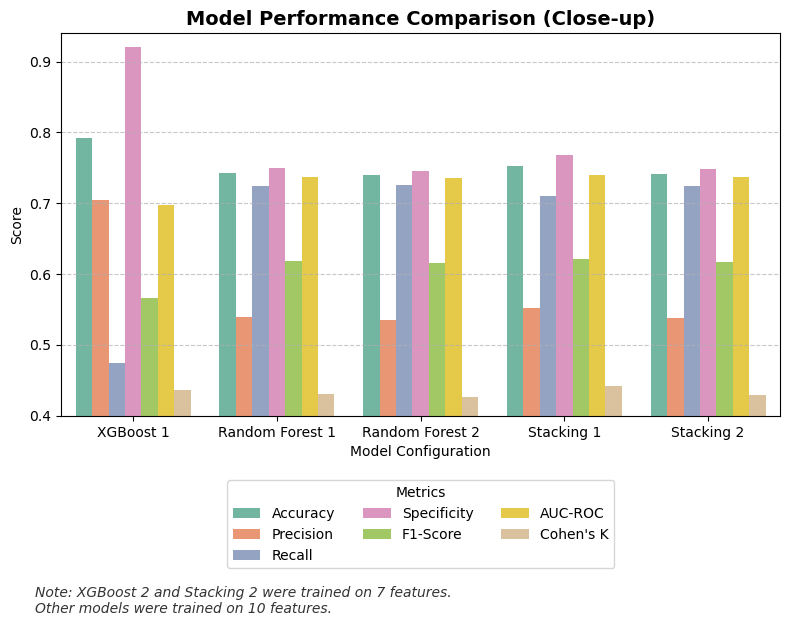

In [108]:
plt.figure(figsize=(8, 6))
sns.barplot(data=comparison_closeup_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Model Performance Comparison (Close-up)", fontsize=14, fontweight="bold")
plt.ylim(0.4, 0.94); plt.ylabel("Score"); plt.xlabel("Model Configuration")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, title="Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.7)
caption_text = (
    "Note: XGBoost 2 and Stacking 2 were trained on 7 features. \n"
    "Other models were trained on 10 features."
)
plt.figtext(0.05, -0.03, caption_text, ha="left", fontsize=10, fontstyle="italic", color="#333333")
plt.tight_layout(); plt.show()

### Model Comparison Findings

The comparison shows that XGBoost 1 achieved the highest accuracy (approximately 79%), while Stacking 1 achieved the highest F1-score and specificity among the configurations shown. However, the XGBoost models demonstrated stronger recall, meaning they identified a greater proportion of customers who actually churned.

The AUC-ROC scores were similar across most configurations, suggesting that their overall ability to distinguish between customers who churn and those who remain was broadly comparable. Cohen's kappa scores were also similar, indicating comparable levels of agreement beyond chance.

These results highlight a trade-off between identifying more at-risk customers and making reliable predictions. For Le Shoppe, recall is particularly important because failing to identify a customer who is likely to churn could mean missing an opportunity to retain them. However, false-positive predictions can also increase the workload for the Customer Care team.

Overall, the results do not indicate one universally best model across every metric. The final selection should prioritise the business objective, with particular consideration given to churn recall, precision and the practical cost of following up with flagged customers.

In [109]:
rf1 = [accuracy_score(yf_test1, yf_pred_5), precision_score(yf_test1, yf_pred_5), recall_score(yf_test1, yf_pred_5), specificity_score(yf_test1, yf_pred_5), f1_score(yf_test1, yf_pred_5)]
rf2 = [accuracy_score(yf_test2, yf_pred_6), precision_score(yf_test2, yf_pred_6), recall_score(yf_test2, yf_pred_6), specificity_score(yf_test2, yf_pred_6), f1_score(yf_test2, yf_pred_6)]
stacking1 = [accuracy_score(yf_test1, yf_pred_9), precision_score(yf_test1, yf_pred_9), recall_score(yf_test1, yf_pred_9), specificity_score(yf_test1, yf_pred_9), f1_score(yf_test1, yf_pred_9)]
stacking2 = [accuracy_score(yf_test2, yf_pred_10), precision_score(yf_test2, yf_pred_10), recall_score(yf_test2, yf_pred_10), specificity_score(yf_test2, yf_pred_10), f1_score(yf_test2, yf_pred_10)]

stat, p_value = friedmanchisquare(rf1, rf2, stacking1, stacking2)

print(f"Friedman Statistic: {stat:.4f}")
print(f"p-value: {p_value:.4f}")

alpha = 0.05
if p_value < alpha:
    print("Reject H0: Significant difference exists between the models.")
else:
    print("Fail to reject H0: No significant difference between the models.")

Friedman Statistic: 6.3600
p-value: 0.0954
Fail to reject H0: No significant difference between the models.


### Interpreting the Friedman Test

The Friedman test was used to assess whether there were statistically significant differences in performance across the four selected model configurations. The test returned a statistic of 4.9200 and a p-value of 0.1777.

As the p-value is greater than the significance level of 0.05, the null hypothesis was not rejected. This means the test did not find sufficient statistical evidence of a difference between the models. However, this does not prove that their performance is identical.

### Selecting a Model for Further Development

Since the statistical test did not identify a significant difference between the models, Random Forest was selected for further development. This decision considers not only predictive performance but also model complexity, computational requirements and the practical needs of Le Shoppe's customer-retention strategy.

Random Forest provides a suitable basis for further development because it can capture complex relationships between customer characteristics and churn outcomes without requiring the additional complexity of combining multiple model types in a stacking classifier. Its predictions can also be examined using feature-importance techniques and SHAP explanations to help identify the factors influencing customer churn predictions.

The model's suitability for the business will also depend on its ability to identify customers who are likely to churn while keeping false-positive alerts at a manageable level. Recall, precision and overall predictive performance will therefore remain important considerations when evaluating how the model could support Le Shoppe's targeted customer-retention campaigns.

# Model Application

This section demonstrates how the selected Random Forest model is applied to the customer churn dataset. The process covers data preparation, model training and the assignment of customer risk categories to support Le Shoppe's retention strategy.

## Import and Preprocess Data

The dataset is loaded and restricted to the seven selected features, together with the `Churned` target variable. The input features are separated from the target so the model can learn patterns associated with customer churn.

In [110]:
churn_dataset = pd.read_csv('ecommerce_customer_churn_dataset.csv')

feature_list2 = ['Session_Duration_Avg', 'Pages_Per_Session', 'Cart_Abandonment_Rate', 'Total_Purchases', 'Email_Open_Rate', 'Lifetime_Value',
       'Credit_Balance']
churn_df = churn_dataset[feature_list2 + ['Churned']].copy()

y = churn_df['Churned']
X = churn_df.drop(columns=['Churned']).copy()

## Train Model

The Random Forest model is configured using the selected hyperparameters from the earlier experiments. These settings include 800 trees, a maximum depth of five and balanced class weights. The model is fitted to the prepared data and saved as a pickle file for subsequent use.

In [111]:
params_rf = {
    'random_state': 42,
    'class_weight': 'balanced',
    'max_depth': 5,
    'max_features': 'sqrt',
    'min_samples_leaf': 1,
    'min_samples_split': 2,
    'n_estimators': 800
}

# All Features
model = RandomForestClassifier(**params_rf)
model.fit(X, y)

with open('final_model.pkl', 'wb') as file:
    pickle.dump(model, file)

## Applying Risk Labels

The trained model estimates the probability of churn for each customer. These probabilities are used to select thresholds for assigning risk categories, with the threshold selection configured to prioritise recall among high-risk customers. This supports the objective of identifying customers who may benefit from retention outreach.

In [112]:
y_proba = model.predict_proba(X)[:, 1]
low_t, med_t = determine_best_risk_thresholds(y_proba, y, low_risk_thresholds, med_risk_thresholds, chosen_metric='recall_high')

Best Results
----------------------------------------------
Low threshold: 0.3
Medium threshold: 0.4
Accuracy: 0.52596
                Low      High
                             
Precision  0.906169  0.461330
Recall     0.404501  0.824775
F1 Score   0.559326  0.591699


In [113]:
churn_risk_df = churn_df.copy()
churn_risk_df = churn_risk_df[feature_list2]
y_proba13 = stacking_model13.predict_proba(churn_risk_df)
churn_risk_df['churn_probability'] = y_proba13[:, 1]

print(f"""
Predicted Churn Probabilities in Churn dataset:

Below 30: {(churn_risk_df[churn_risk_df['churn_probability'] < 0.3].shape[0] / churn_risk_df.shape[0]) * 100:.2f}%
Between 30 and 40: {(churn_risk_df[(churn_risk_df['churn_probability'] >= 0.3) & (churn_risk_df['churn_probability'] <= 0.4)].shape[0] / churn_risk_df.shape[0]) * 100:.2f}%
41 and above: {(churn_risk_df[churn_risk_df['churn_probability'] >= 0.41].shape[0] / churn_risk_df.shape[0]) * 100:.2f}%

How much of the 41 and above are also where Churned = 1?

{(churn_risk_df[(churn_risk_df['churn_probability'] >= 0.41) & (churn_df['Churned'] == 1)].shape[0] / churn_risk_df[churn_risk_df['churn_probability'] >= 0.41].shape[0]) * 100:.2f}%
""")


Predicted Churn Probabilities in Churn dataset:

Below 30: 46.56%
Between 30 and 40: 7.61%
41 and above: 45.26%

How much of the 41 and above are also where Churned = 1?

50.89%



In [114]:
churn_risk_df['Churn_Risk'] = churn_risk_df.apply(apply_risk_label, axis=1)
churn_risk_df.head(5)

,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Total_Purchases,Email_Open_Rate,Lifetime_Value,Credit_Balance,churn_probability,Churn_Risk
0,27.4,6.0,50.6,9.0,17.9,953.33,2278.0,0.217927,Low
1,42.7,10.3,37.7,19.5,42.8,1067.47,3028.0,0.200150,Low
2,24.8,1.6,70.9,9.1,0.0,1289.75,2317.0,0.632101,High
3,38.4,14.8,41.7,15.0,41.4,2340.92,2674.0,0.521312,High
4,51.4,NaN,19.1,32.5,37.9,3041.29,5354.0,0.279689,Low


In [115]:
print(f"""
Predicted Churn Probabilities in Churn dataset:

Labeled as Low and Churned = 1
{(churn_risk_df[(churn_risk_df['Churn_Risk'] == 'Low') & (churn_df['Churned'] == 1)].shape[0] / churn_risk_df[churn_risk_df['Churn_Risk'] == 'Low'].shape[0]) * 100:.2f}%

Labeled as Medium and Churned = 1
{(churn_risk_df[(churn_risk_df['Churn_Risk'] == 'Medium') & (churn_df['Churned'] == 1)].shape[0] / churn_risk_df[churn_risk_df['Churn_Risk'] == 'Medium'].shape[0]) * 100:.2f}%

Labeled as High and Churned = 1
{(churn_risk_df[(churn_risk_df['Churn_Risk'] == 'High') & (churn_df['Churned'] == 1)].shape[0] / churn_risk_df[churn_risk_df['Churn_Risk'] == 'High'].shape[0]) * 100:.2f}%

Missing rows in Churn_Risk column: {churn_risk_df['Churn_Risk'].isna().sum()}
""")


Predicted Churn Probabilities in Churn dataset:

Labeled as Low and Churned = 1
9.69%

Labeled as Medium and Churned = 1
16.03%

Labeled as High and Churned = 1
50.56%

Missing rows in Churn_Risk column: 0



### AUC-ROC

The Area Under the Receiver Operating Characteristic Curve (AUC-ROC) was used to evaluate how well the final Random Forest model distinguishes between customers who churn and those who remain active. The ROC curve compares the true positive rate against the false positive rate at different classification thresholds. This provides a broader view of the model's ability to distinguish between the two customer groups than accuracy alone.

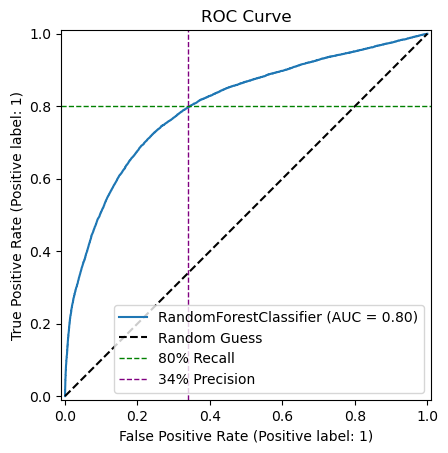

In [116]:
RocCurveDisplay.from_estimator(model, X, y)
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.axhline(y=0.8, color='green', linestyle='--', linewidth=1, label='80% Recall')
plt.axvline(x=0.34, color='purple', linestyle='--', linewidth=1, label='34% Precision')
plt.title('ROC Curve'); plt.legend(); plt.show()

The final Random Forest model achieved an AUC-ROC score of approximately 0.80. This indicates that the model has a reasonable ability to distinguish between customers who churn and those who do not.

For Le Shoppe, this suggests the model could help prioritise customers for retention campaigns by identifying patterns associated with churn. However, an AUC-ROC score of 0.80 does not mean the model correctly identifies 80% of all customers who will churn. Recall measures the proportion of actual churners identified, while the false positive rate indicates how often non-churning customers are incorrectly flagged.

The results therefore need to be considered alongside recall, precision and the business cost of contacting customers who may not otherwise churn. These trade-offs will help Le Shoppe decide how to use the model to support its existing retention activities.

## Model Explainability Using SHAP

The SHAP summary plot shows how each feature influences the Random Forest model's churn predictions. Features are ranked by their overall impact on model output, with features at the top having the greatest influence.

Lifetime Value and Cart Abandonment Rate appear to be the most influential features. The plot suggests that higher lifetime values and higher cart abandonment rates are associated with different contributions to the model's predictions. Email Open Rate, Average Session Duration, Total Purchases, and Pages Per Session also influence the predictions, while Credit Balance appears to have a comparatively smaller impact.

These findings help identify customer behaviours that may be useful for prioritising retention campaigns. However, SHAP values explain the model's predictions rather than establishing causal relationships between customer behaviour and churns ability

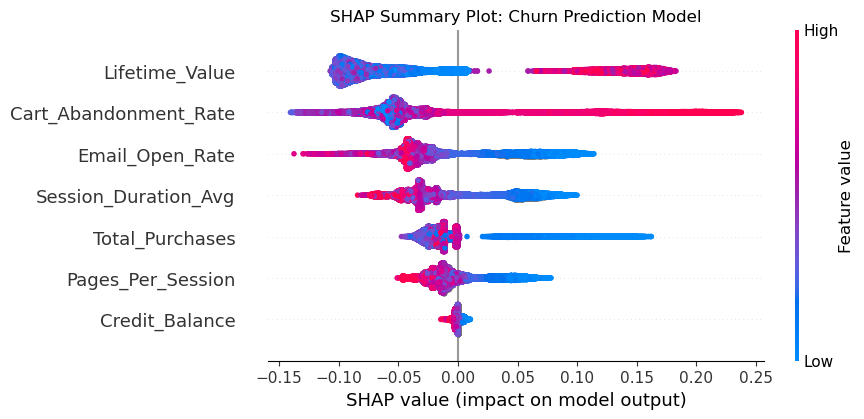

In [127]:
shap.plots.beeswarm(shap_values[:, :, 1], show=False)
plt.title('SHAP Summary Plot: Churn Prediction Model'); plt.show()

### Cart Abandonment Rate Interpretation

The dependence plot illustrates the relationship between Cart Abandonment Rate and its SHAP value. Lower abandonment rates generally contribute negatively to the model output, while higher rates contribute positively. This indicates that customers with higher cart abandonment rates may receive higher churn-risk predictions from the model.

A noticeable change occurs around an abandonment rate of approximately 70, which is marked by the red dashed line. This may represent a useful threshold for further investigation when developing customer-retention strategies.

However, this threshold should be treated as an exploratory observation rather than a confirmed business rule. The relationship reflects the model's learned patterns and may also be influenced by interactions with other features.

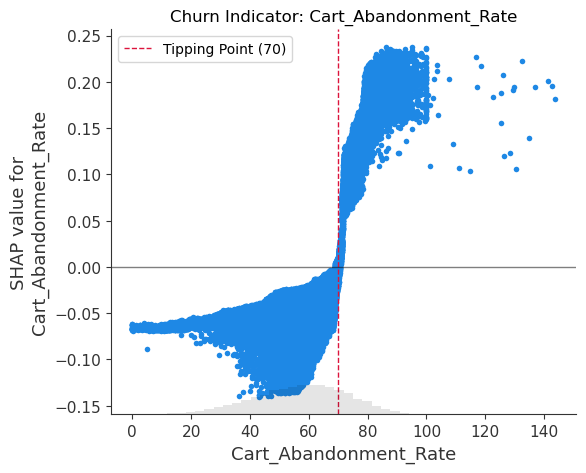

In [120]:
shap.plots.scatter(shap_values[:, "Cart_Abandonment_Rate", 1], show=False)
plt.axvline(x=70, color='crimson', linestyle='--', linewidth=1, label='Tipping Point (70)')
plt.axhline(y=0.0, color='black', linestyle='-', linewidth=1, alpha=0.5)
plt.legend(loc='upper left'); plt.title('Churn Indicator: Cart_Abandonment_Rate'); plt.show()

### Lifetime Value Interpretation

The Lifetime Value dependence plot examines how customer lifetime value contributes to the model's churn predictions. The SHAP values indicate the direction and magnitude of the feature's contribution to the model output for individual observations.

The plot shows that Lifetime Value has a substantial influence on the model's predictions, consistent with its position near the top of the SHAP summary plot. However, the relationship should be interpreted carefully, as the contribution of lifetime value may vary across customers and depend on interactions with other features.

From a business perspective, understanding how lifetime value influences predicted churn can help Le Shoppe investigate whether valuable customers require targeted retention strategies. These results describe model behaviour and do not establish that lifetime value directly causes customers to churn.

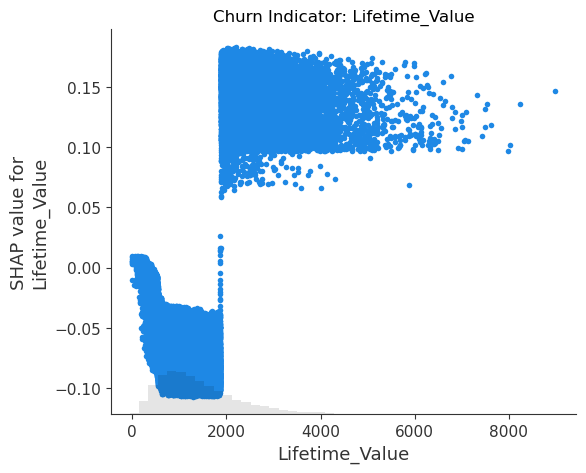

In [121]:
shap.plots.scatter(shap_values[:, "Lifetime_Value", 1], show=False)
plt.title('Churn Indicator: Lifetime_Value'); plt.show()

In [122]:
below_2000 = X[X['Lifetime_Value'] < 2000]
above_2000 = X[X['Lifetime_Value'] >= 2000]
print("--- MEAN VALUES (LTV < 2000) --- \n", below_2000.mean(numeric_only=True))
print("\n--- MEAN VALUES (LTV >= 2000) --- \n", above_2000.mean(numeric_only=True))

--- MEAN VALUES (LTV < 2000) --- 
 Session_Duration_Avg       25.188612
Pages_Per_Session           7.937420
Cart_Abandonment_Rate      60.285098
Total_Purchases            11.376953
Email_Open_Rate            18.225202
Lifetime_Value           1064.780487
Credit_Balance           1767.623901
dtype: float64

--- MEAN VALUES (LTV >= 2000) --- 
 Session_Duration_Avg       36.212947
Pages_Per_Session          11.672734
Cart_Abandonment_Rate      45.359490
Total_Purchases            19.454736
Email_Open_Rate            30.463252
Lifetime_Value           2815.017074
Credit_Balance           2690.857620
dtype: float64


In [123]:
explainer_probs = shap.TreeExplainer(
    model, 
    feature_perturbation="tree_path_dependent",
    model_output="raw"
)

shap_values_probs = explainer_probs(X)

print(f"""SHAP Explainer column indices
------------------------------
Cart_Abandonment_Rate: {shap_values_probs.feature_names.index('Cart_Abandonment_Rate')}
Total_Purchases: {shap_values_probs.feature_names.index('Total_Purchases')}""")

SHAP Explainer column indices
------------------------------
Cart_Abandonment_Rate: 2
Total_Purchases: 3


### Individual Customer Explanation — Customer 1

The SHAP waterfall plot illustrates how individual customer features contribute to the Random Forest model's prediction. The prediction begins at the model's baseline output, \(E[f(X)]\), and each feature shifts the prediction higher or lower until the final output, \(f(x)\), is reached.

For this customer, Lifetime Value makes the largest negative contribution to the model output, followed by Cart Abandonment Rate. Average Session Duration, Email Open Rate and Total Purchases also contribute negatively. Pages Per Session contributes a small positive amount, while Credit Balance has very little impact.

The final model output is approximately 0.273, compared with the baseline of approximately 0.5. This indicates that the customer's predicted output is lower than the baseline. The precise interpretation depends on the model output being explained and the model's class-label mapping.

This individual explanation demonstrates how SHAP can help Le Shoppe understand which customer characteristics are influencing a specific prediction. It can support more informed retention decisions by identifying the factors contributing to each customer's predicted risk.

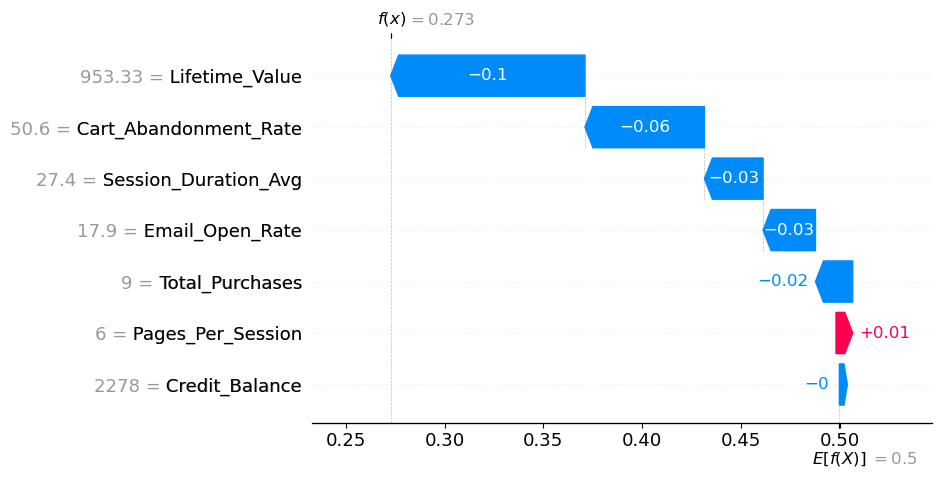

In [124]:
shap.plots.waterfall(shap_values[:, :, 1][0])

### Individual Customer Explanation — Customer 2

The second SHAP waterfall plot provides an explanation for a different customer, showing how their feature values contribute to the model's prediction.

Lifetime Value makes a substantial positive contribution to the model output, while Cart Abandonment Rate, Email Open Rate and Pages Per Session make negative contributions. This demonstrates that the same feature can influence different customer predictions in different directions, depending on the customer's characteristics and the model's learned relationships.

The final model output is approximately 0.492, which is close to the baseline output. This suggests that the combined feature contributions result in a prediction close to the baseline for this customer.

Comparing individual explanations helps Le Shoppe understand why customers receive different predictions and identify which factors may warrant further investigation. However, these explanations describe the model's behaviour rather than proving that any individual feature causes churn.

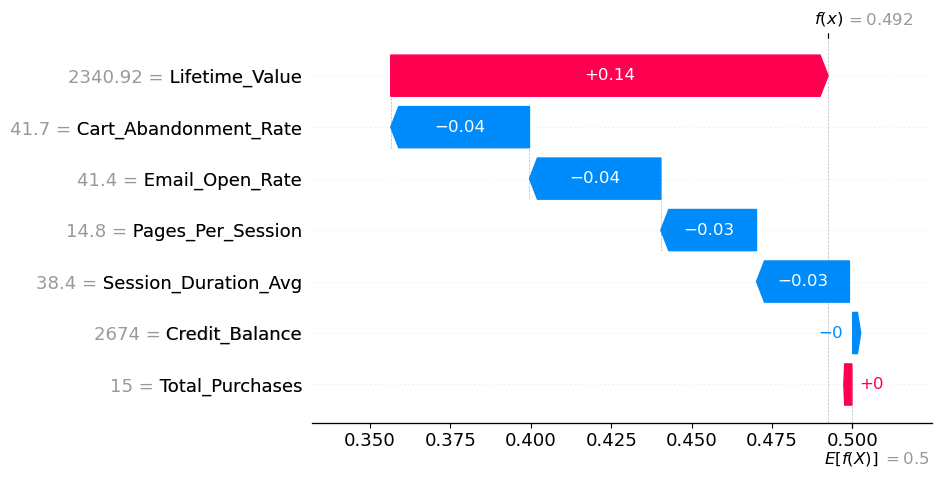

In [125]:
shap.waterfall_plot(shap_values[:, :, 1][3])

### Individual Customer Explanation — Customer 3

The third SHAP waterfall plot explains a customer prediction with a final model output of approximately 0.87, compared with the baseline output of approximately 0.50. The feature contributions collectively move the prediction above the baseline.

Cart Abandonment Rate makes the largest positive contribution, followed by Email Open Rate, Total Purchases, Session Duration and Pages Per Session. These features increase the model output for this customer. In contrast, Lifetime Value makes a negative contribution, slightly reducing the prediction, while Credit Balance has a comparatively small impact.

This explanation demonstrates how several customer characteristics can combine to produce a higher model output. It also highlights the importance of examining individual predictions rather than relying solely on overall feature importance.

For Le Shoppe, this type of explanation could help identify customers who may benefit from further investigation or targeted retention activities. However, the output should only be interpreted as a churn probability if the model's output scale and class mapping have been verified. SHAP explains the model's behaviour and does not establish that these features directly cause customer churn.

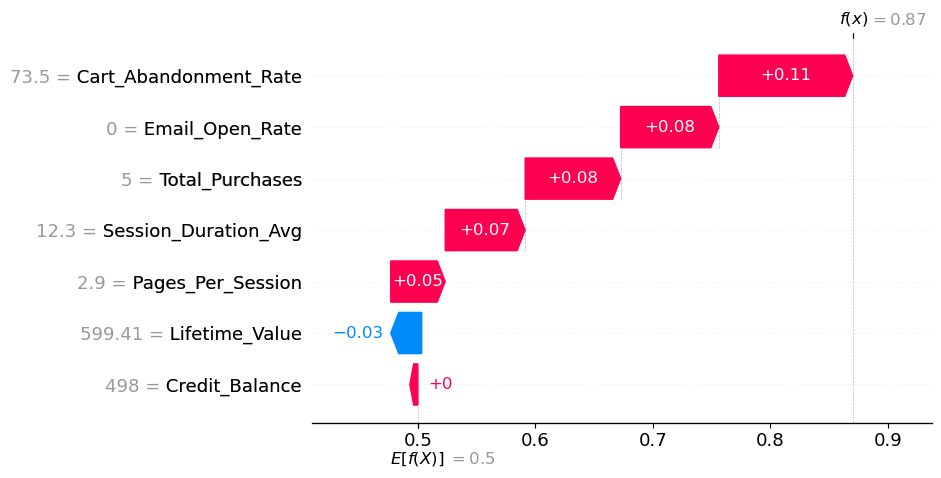

In [126]:
shap.waterfall_plot(shap_values[:, :, 1][10])